# 大规模拉曼成像光谱的塑料分类与跨图评价

《机器学习在物质科学中的应用》课程项目 · **10分钟展示＋5分钟答问**

**研究问题：未参与训练的拉曼采集图中，能否逐谱识别塑料与背景？复杂模型、预处理和更多训练图是否稳定改善识别？**

首轮真实15类六图测试：PCA64＋线性SVM准确率 **72.53%**、宏F1 **0.5873**；
增强CNN三训练种子宏F1 **0.5725 ± 0.0181**。
扩展12类三折开发研究完成 **75次神经训练＋9组传统基线**，
baseline:pca64_linear_svm的外折平均宏F1在预设条件中最高，为 **0.8742 ± 0.0721**。

**两个任务的类别和评价图不同，分数不能直接解释成从首轮到扩展的性能提升。**
前述±分别是同一六图测试上的训练种子标准差、三外折标准差，含义不同；均不是置信区间。

汇报节奏：问题0:00–0:45；数据与表示0:45–2:15；划分和方法2:15–3:45；首轮结果3:45–5:00；
扩展方法比较5:00–6:15；消融与学习曲线6:15–8:15；局限、结论与分工8:15–10:00。
后附误差、校准、权重读取和复现代码供5分钟问答查阅，不逐项宣读。

In [1]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
from sklearn.metrics import accuracy_score, recall_score, f1_score
%matplotlib inline
ROOT = Path.cwd()
if not (ROOT/'data/processed/dataset.npz').is_file():
    raise RuntimeError('请在解压后的项目根目录启动Notebook。')
STUDY = ROOT/'extension_study'
SUMMARY = STUDY/'results/summary'
sys.path[:0] = [str(ROOT/'src'), str(STUDY/'src')]
from common import SHORT
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,'figure.dpi':120,
                     'axes.spines.top':False,'axes.spines.right':False})
def load_json(path):
    return json.loads(Path(path).read_text(encoding='utf-8'))
audit = load_json(ROOT/'data/processed/data_audit.json')
split_protocol = load_json(ROOT/'data/processed/split_protocol.json')
study_protocol = load_json(STUDY/'protocol/splits.json')
plan = load_json(STUDY/'protocol/experiment_plan.json')
validation = load_json(SUMMARY/'run_validation.json')
independent = load_json(STUDY/'results/independent_audit.json')
assert validation['status']=='complete' and validation['validated_runs']==84
assert independent['status']=='passed' and independent['verified_total']==84
formal = pd.read_csv(ROOT/'results/final_test/model_comparison.csv')
conditions = pd.read_csv(SUMMARY/'condition_summary.csv')
assert conditions.complete.all()
print('结果读取与独立审计：84/84；本Notebook默认不训练模型。')

结果读取与独立审计：84/84；本Notebook默认不训练模型。


## 1．问题、数据与表示（0:00–2:15）

拉曼谱反映分子振动，像素级采集还包含背景与不同信噪比。本项目以1024点处理后光谱为输入，以材料标签为输出，
比较匹配基线、经典机器学习及一维神经网络。原始数据来自RaMPI开放仓库，而非把模拟谱或增强谱计入样本量。

34张采集map共33,119条像素谱，含14种塑料及blank背景。**像素谱、采集图、独立物理标本是不同统计单位。**
数据未提供可核验的粒子/物理标本ID或可靠二维坐标，因此只研究按图隔离的逐谱分类，不绘制虚构二维分割图。

频轴取34图交集710.1758–1827.0 cm⁻¹，线性插值1024点；逐谱SG平滑(11,3)、两端各5点均值线性基线扣除、SNV(ddof=0)。
逐谱变换不使用全体类别均值；PCA和标准化只在相应训练部分拟合。

In [2]:
display(pd.DataFrame({'项目':['采集map','像素谱','塑料像素','背景像素','含背景类别','输入特征点'],
    '数量':[audit['map_count'],audit['retained_spectra_count'],
    audit['metadata_reconciliation']['actual_retained_plastic_spectra'],
    audit['metadata_reconciliation']['actual_retained_blank_spectra'],audit['class_count'],audit['features']]}))
split = pd.read_csv(ROOT/'data/processed/map_split.csv')
display(split.groupby('split').agg(map数=('map_id','size'),像素谱数=('pixels','sum')))
assert split.map_id.is_unique

,项目,数量
0,采集map,34
1,像素谱,33119
2,塑料像素,16598
3,背景像素,16521
4,含背景类别,15
5,输入特征点,1024


,map数,像素谱数
split,,
test,6,6399
train,22,20968
validation,6,5752


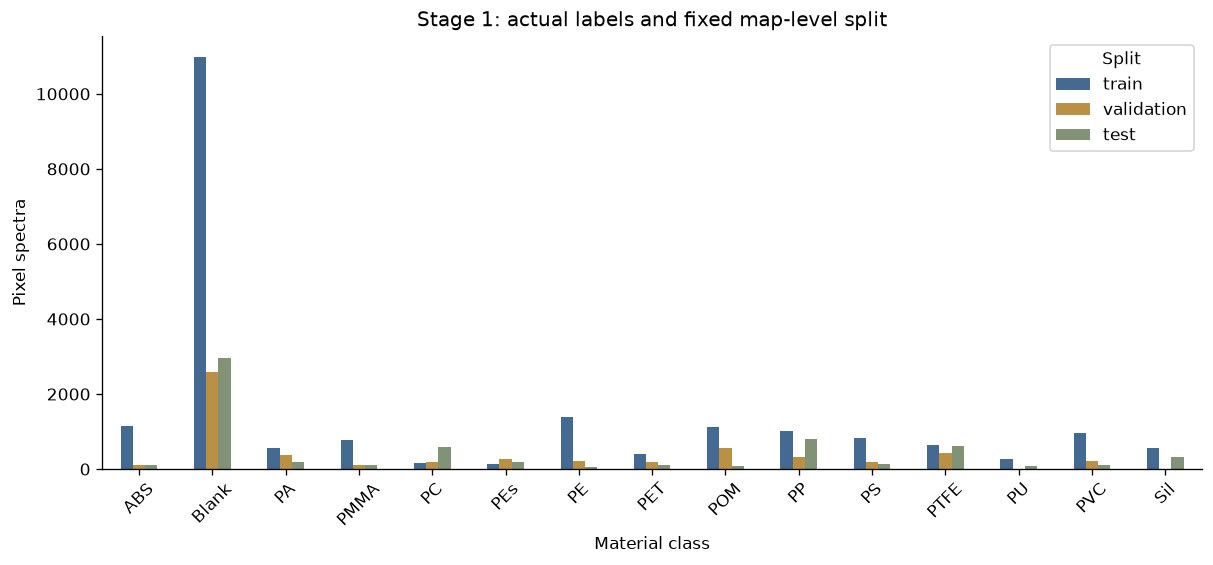

In [3]:
coverage = pd.read_csv(ROOT/'data/processed/class_split_coverage.csv',index_col=0)
coverage.index = [SHORT.get(label,label) for label in coverage.index]
fig, ax = plt.subplots(figsize=(10,4.6),layout='constrained')
coverage[['train','validation','test']].plot.bar(ax=ax,rot=45,color=['#446A91','#B99044','#819276'])
ax.set(xlabel='Material class',ylabel='Pixel spectra',title='Stage 1: actual labels and fixed map-level split')
ax.legend(title='Split')
plt.show()

背景约占一半，因此同时报告宏F1及图等权宏F1，避免只看背景主导的像素准确率。
实际CSV计数为塑料16,598、blank16,521；源元表/论文计数与三张图存在差异，审计保留原逐行标签，没有为匹配论文修改标签。
下图只从首轮训练图各取一条预先指定材料谱，纵轴缩放与偏移仅用于显示。

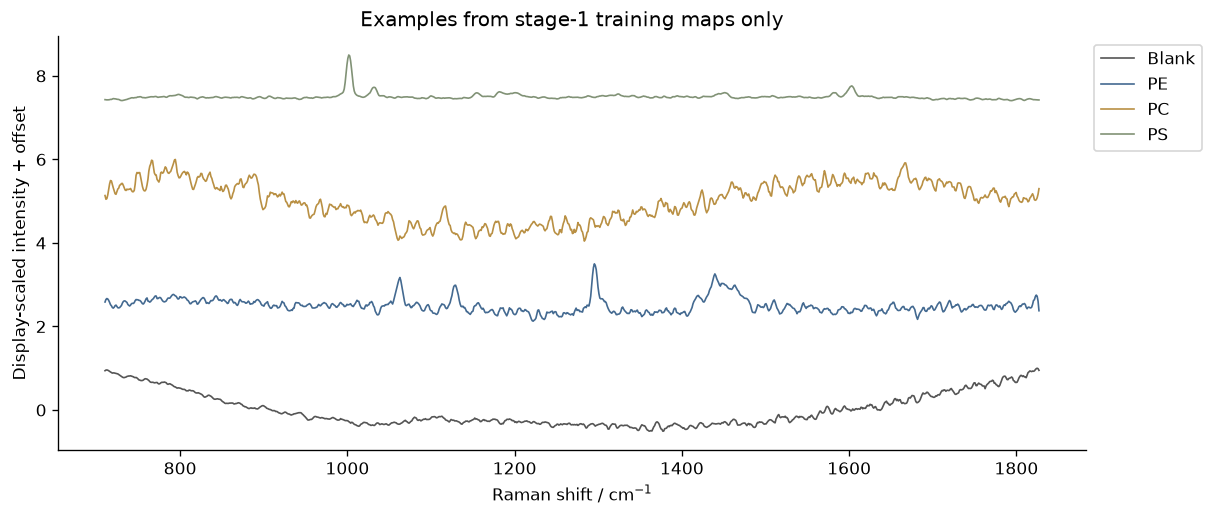

In [4]:
with np.load(ROOT/'data/processed/dataset.npz',allow_pickle=False) as archive:
    X = archive['X']; text_y = archive['y'].astype(str)
    groups = archive['groups'].astype(str); wn = archive['wavenumbers']
train_maps = set(split.loc[split.split=='train','map_id'])
fig,ax = plt.subplots(figsize=(10,4.2),layout='constrained')
for offset,(label,color) in enumerate(zip(['blank','polyethylene','polycarbonate','polystyrene'],
                                           ['#555555','#446A91','#B99044','#819276'])):
    index = np.flatnonzero((text_y==label)&np.isin(groups,list(train_maps)))[0]
    trace = X[index]/np.max(np.abs(X[index]))
    ax.plot(wn,trace+offset*2.5,label=SHORT.get(label,label),color=color,linewidth=1)
ax.set(xlabel='Raman shift / cm$^{-1}$',ylabel='Display-scaled intensity + offset',title='Examples from stage-1 training maps only')
ax.legend(loc='upper left',bbox_to_anchor=(1,1))
plt.show()
del X,text_y,groups

## 2．两阶段评价协议与模型（2:15–3:45）

| 阶段 | 研究总体与类别 | 训练/选型 | 最终评价及其边界 |
| --- | --- | --- | --- |
| 首轮正式测试 | 34map、33,119像素、15类 | 22训练图；6验证图选C/epoch，验证仅13类有真值 | 固定6测试图、6,399像素、15类；只评价一次后冻结 |
| 扩展开发研究 | 仅原训练＋验证的28图；保留25,541像素、12共同类 | 3外折，每外折再分内训练/5图内验证；内验证选C/epoch | 外评价9/9/10图；原6测试图完全排除；属于开发阶段比较 |

共同类规则先于新增拟合冻结：只保留在28开发图中至少出现于3图的标签，因此排除PC、PU、Sil像素；不按分数筛类。
神经网络只拟合内训练并保留内验证最佳权重，**不再用整个外训练集合重拟合**；外折不调参。
每折先平均3个训练种子，再对3折求均值和样本标准差，不能把9次结果当作9套独立样本。

- 余弦类中心：简单谱匹配参照；PCA64＋线性SVM：低维线性边界，C∈{0.1,1,10}仅由内验证选。
- 随机森林：300树、叶节点最少2，经典非线性对照。
- 1D-CNN：局部谱形，12类320,076参数；MLP(1024→512→256→12)：全连接参照，660,748参数。
- 1D-ResNet：32/64/128/256通道、每阶段2残差块、8bin自适应池化保留粗谱位置，1,227,372参数。

神经网络采用AdamW(lr=0.001、weight_decay=0.0001)、batch256、梯度裁剪5、余弦学习率；扩展最多120轮、早停耐心18。
三模型均从头训练、没有外部预训练权重、未逐模型调学习率；相同训练策略下的对比不代表各架构已达最优。

In [5]:
display(pd.read_csv(STUDY/'protocol/role_counts.csv'))
eligible = pd.read_csv(STUDY/'protocol/class_eligibility.csv')
display(eligible)
assert plan['original_test_reuse'] is False
print('扩展共同类：',[SHORT.get(s,s) for s in study_protocol['labels']])

,fold_id,role,maps,pixels,classes_present,missing_classes
0,1,inner_train,13,10859,12,NaN
1,1,inner_val,5,5545,12,NaN
2,1,outer_eval,10,9137,12,NaN
3,2,inner_train,14,11410,12,NaN
4,2,inner_val,5,5386,12,NaN
5,2,outer_eval,9,8745,12,NaN
6,3,inner_train,14,13458,12,NaN
7,3,inner_val,5,4424,12,NaN
8,3,outer_eval,9,7659,12,NaN


,label,development_maps,development_pixels,eligible,exclusion_reason
0,acrylonitrile butadiene styrene,5,1251,True,NaN
1,blank,28,13566,True,NaN
2,nylon,4,941,True,NaN
3,poly (methyl methacrylate),5,892,True,NaN
4,polycarbonate,2,360,False,development_map_coverage_below_3
5,polyester,3,405,True,NaN
6,polyethylene,7,1604,True,NaN
7,polyethylene terephthalate,3,597,True,NaN
8,polyoxymethylene,6,1678,True,NaN
9,polypropylene,4,1343,True,NaN


扩展共同类： ['ABS', 'Blank', 'PA', 'PMMA', 'PEs', 'PE', 'PET', 'POM', 'PP', 'PS', 'PTFE', 'PVC']


## 3．首轮15类六图正式结果（3:45–5:00）

以下分数来自首轮保存的正式测试预测。增强CNN三种子汇总反映训练随机性；无增强仅seed42的单次配对不能支持稳定因果结论。
该六图结果现在保持冻结，不参与新增模型或参数选择。验证13类与测试15类口径不同，不能把两者差值全部称为域迁移损失。

In [6]:
display(formal[['model','accuracy','macro_f1_present','map_equal_weight_macro_f1','map_mean_accuracy']].round(4))
aug = formal[formal.model.str.match(r'^cnn_aug_seed\d+$')]
display(aug[['accuracy','macro_f1_present','map_equal_weight_macro_f1']].agg(['mean','std']).round(4))

,model,accuracy,macro_f1_present,map_equal_weight_macro_f1,map_mean_accuracy
0,cosine_centroid,0.6487,0.4471,0.4942,0.7227
1,pca64_linear_svm,0.7253,0.5873,0.6216,0.7884
2,cnn_aug_seed42,0.6982,0.5530,0.5982,0.7725
3,cnn_aug_seed43,0.7089,0.5757,0.6091,0.7760
4,cnn_aug_seed44,0.7078,0.5887,0.6148,0.7747
5,cnn_noaug_seed42,0.7160,0.5733,0.6072,0.7797


,accuracy,macro_f1_present,map_equal_weight_macro_f1
mean,0.7050,0.5725,0.6074
std,0.0058,0.0181,0.0084


### 六图测试的模型比较

比较来自同一15类测试集；不将最好的单种子当作增强CNN整体结论。

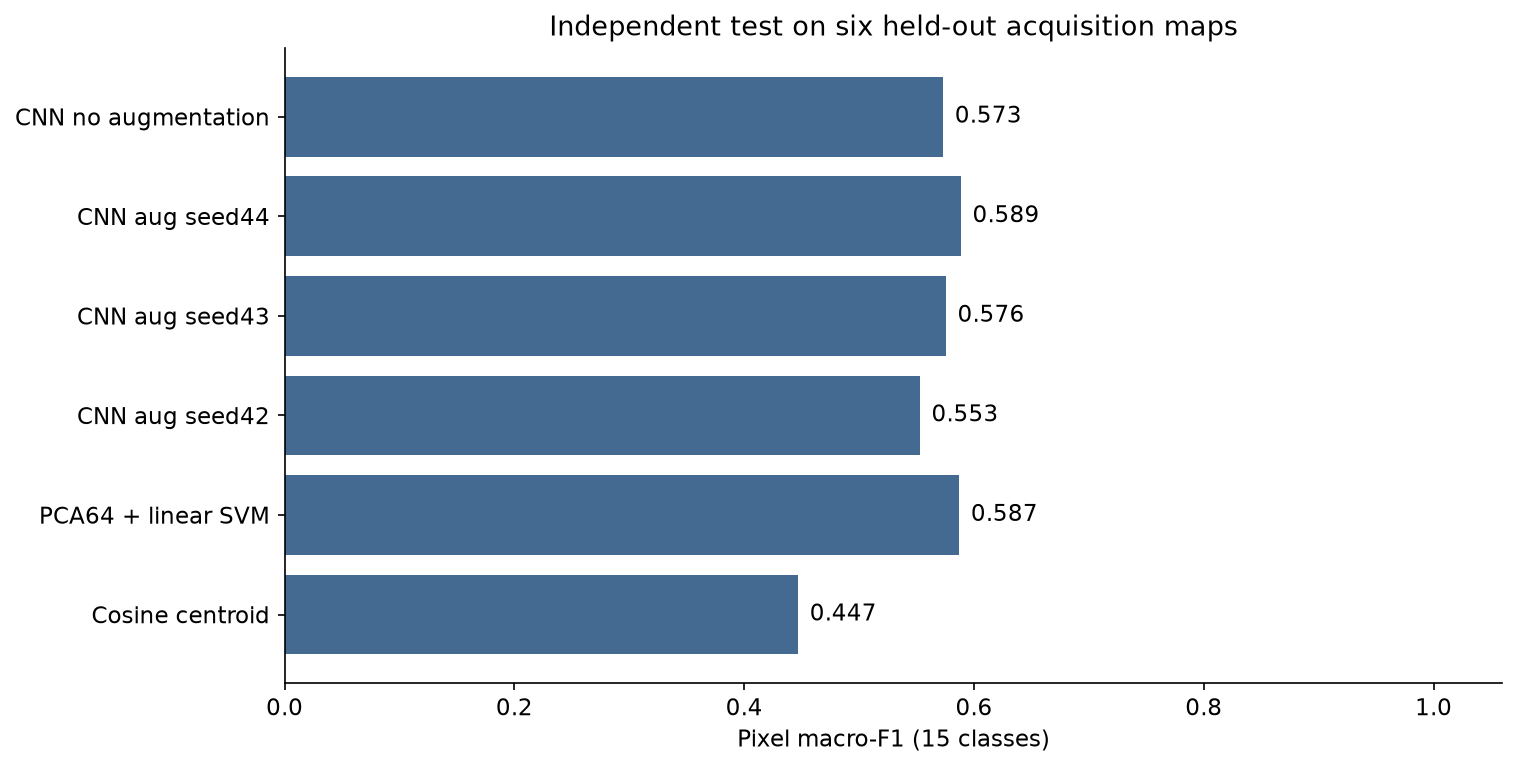

In [7]:
display(Image(filename=str(ROOT / 'results/final_test/figures/01_model_comparison.png'), width=1050))

### 逐图误差支持的适用范围

同一模型在不同图上的表现差异说明只给总体像素分数不足。PC_2、环境混合图等需结合逐类混淆复核；不能由此直接断言采集域是唯一原因。

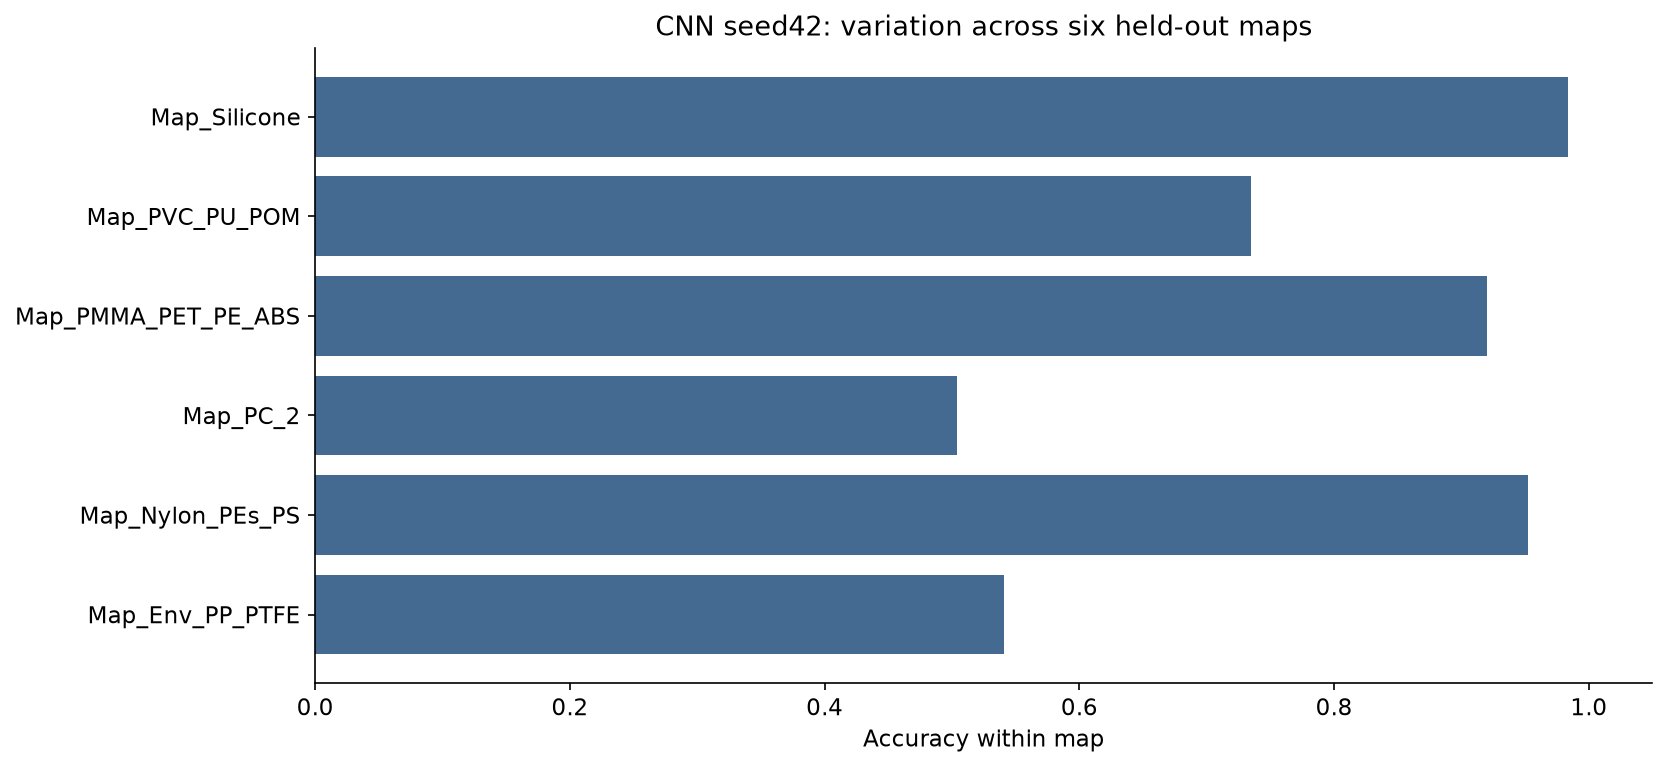

In [8]:
display(Image(filename=str(ROOT / 'results/final_test/figures/04_per_map_accuracy.png'), width=1050))

## 4．扩展12类三折开发比较（5:00–6:15）

本阶段比较架构与传统基线，评价覆盖12类且原测试图不进入输入。点和误差棒为3外折均值±折间标准差；神经网络每折先平均3种子。
3折标准差是描述性的离散程度，训练集相互重叠，不是独立标本置信区间或显著性检验。

,condition,accuracy_mean,accuracy_fold_sd,macro_f1_present_mean,macro_f1_present_fold_sd,map_equal_weight_macro_f1_mean,map_equal_weight_macro_f1_fold_sd
0,architecture:cnn,0.9230,0.0347,0.8687,0.0629,0.8560,0.0627
1,architecture:mlp,0.9148,0.0402,0.8490,0.0813,0.8375,0.0898
2,architecture:resnet,0.9129,0.0409,0.8560,0.0644,0.8482,0.0603
3,baseline:cosine_centroid,0.7990,0.0251,0.6746,0.0832,0.6690,0.1091
4,baseline:pca64_linear_svm,0.9303,0.0368,0.8742,0.0721,0.8635,0.0802
5,baseline:random_forest_300,0.8985,0.0614,0.8310,0.1041,0.8234,0.1058


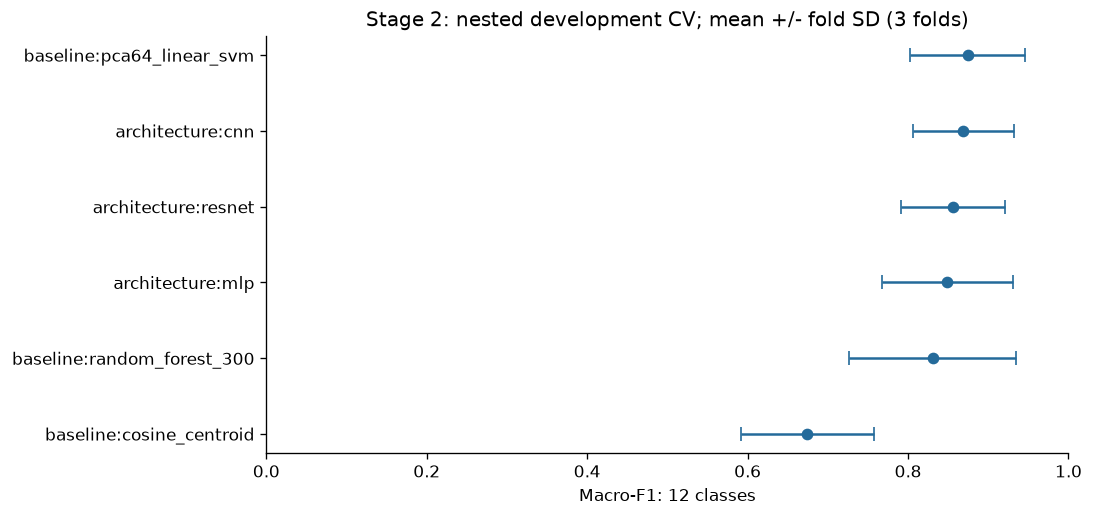

In [9]:
main = conditions[conditions.condition.str.startswith(('architecture:','baseline:'))].copy()
display(main[['condition','accuracy_mean','accuracy_fold_sd','macro_f1_present_mean',
              'macro_f1_present_fold_sd','map_equal_weight_macro_f1_mean','map_equal_weight_macro_f1_fold_sd']].round(4))
# 保留可直接编辑的绘图代码；其余图也可用extension_study/src/summarize_study.py重画。
ordered = main.sort_values('macro_f1_present_mean')
fig,ax = plt.subplots(figsize=(9,4.2),layout='constrained')
ypos = np.arange(len(ordered))
ax.errorbar(ordered.macro_f1_present_mean,ypos,xerr=ordered.macro_f1_present_fold_sd,
            fmt='o',capsize=4,color='#246A9A')
ax.set(yticks=ypos,yticklabels=ordered.condition,xlim=(0,1),xlabel='Macro-F1: 12 classes',
       title='Stage 2: nested development CV; mean +/- fold SD (3 folds)')
plt.show()

## 5．配对消融与训练图学习曲线（6:15–8:15）

增强/损失消融使用同折同种子配对差值。预处理只用seed101，**所有五种表示都关闭增强**，默认参照为每折noaug CNN seed101；
这样避免L2/SNV数值尺度不同导致固定绝对增强噪声强度混杂。处理方案修订发生于新增拟合之前，见extension_study/protocol/plan_revision.md。
正差值表示相应变体宏F1高于其匹配参照，不能扩大成普遍物理规律。

In [10]:
paired = pd.read_csv(SUMMARY/'paired_ablation_summary.csv')
paired_display=paired[['condition','macro_f1_present_mean','macro_f1_present_fold_sd','accuracy_mean','accuracy_fold_sd']].rename(columns={
    'macro_f1_present_mean':'Δ宏F1（变体−参照）','macro_f1_present_fold_sd':'Δ宏F1折间SD',
    'accuracy_mean':'Δ准确率（变体−参照）','accuracy_fold_sd':'Δ准确率折间SD'})
display(paired_display.round(4))
for config in plan['configs']:
    if config['family']=='preprocessing':
        assert config['augment'] is False and config['seed']==101
        reference = next(c for c in plan['configs'] if c['run_id']==f"noaug_cnn_f{config['fold_id']}_s101")
        assert reference['augment'] is False and reference['variant']=='default'

,condition,Δ宏F1（变体−参照）,Δ宏F1折间SD,Δ准确率（变体−参照）,Δ准确率折间SD
0,noaug:cnn,-0.0035,0.0031,-0.0021,0.0016
1,preprocessing:l2,-0.0018,0.0277,0.0034,0.0199
2,preprocessing:no_baseline,0.0023,0.0340,0.0075,0.0228
3,preprocessing:no_sg,0.0037,0.0046,0.0034,0.0051
4,preprocessing:quadratic,-0.0026,0.0238,0.0030,0.0159
5,unweighted:cnn,-0.0004,0.0055,-0.0023,0.0020


### 增强与类别损失的配对影响

同折同种子先作差，每折平均3种子差值，再报告3折均值±折间标准差；没有使用新增外折分数挑选消融条件。

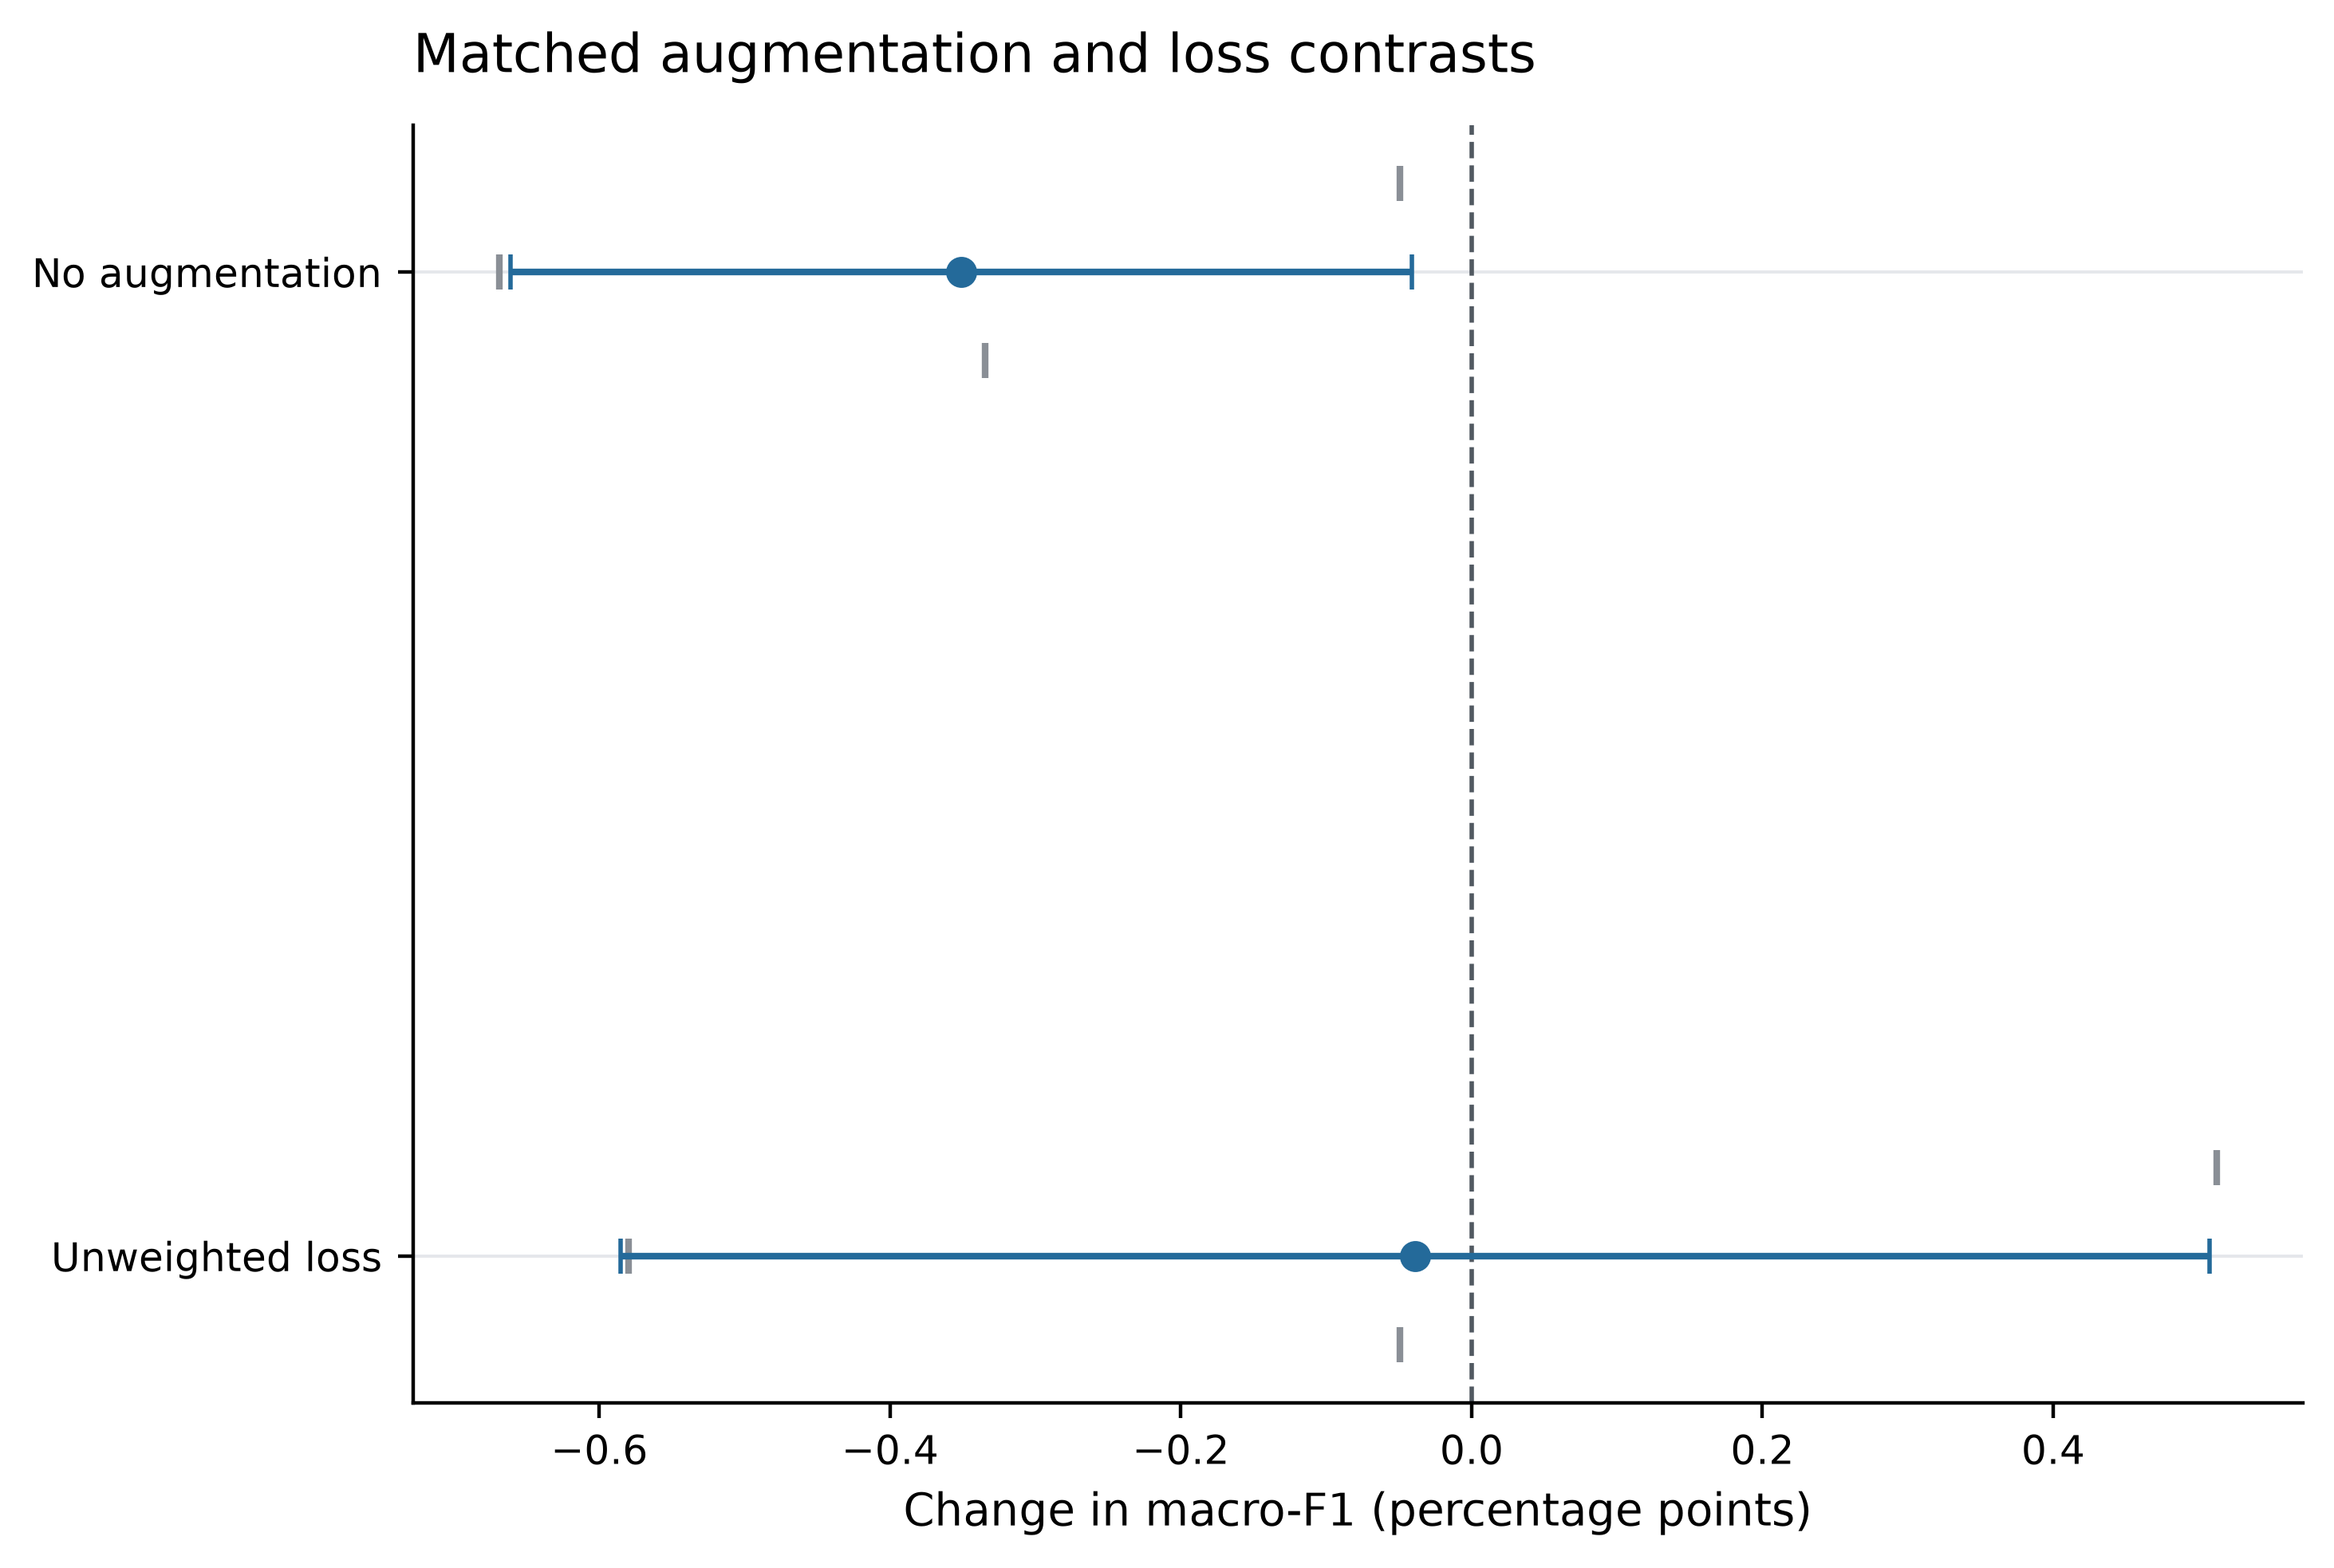

In [11]:
display(Image(filename=str(ROOT / 'extension_study/results/summary/figures/augmentation_loss_paired.png'), width=1050))

### 预处理配对影响

无增强默认CNN seed101为参照；各预处理变体同折同seed101，仅3次配对，不能与增强默认CNN混作一个基线。

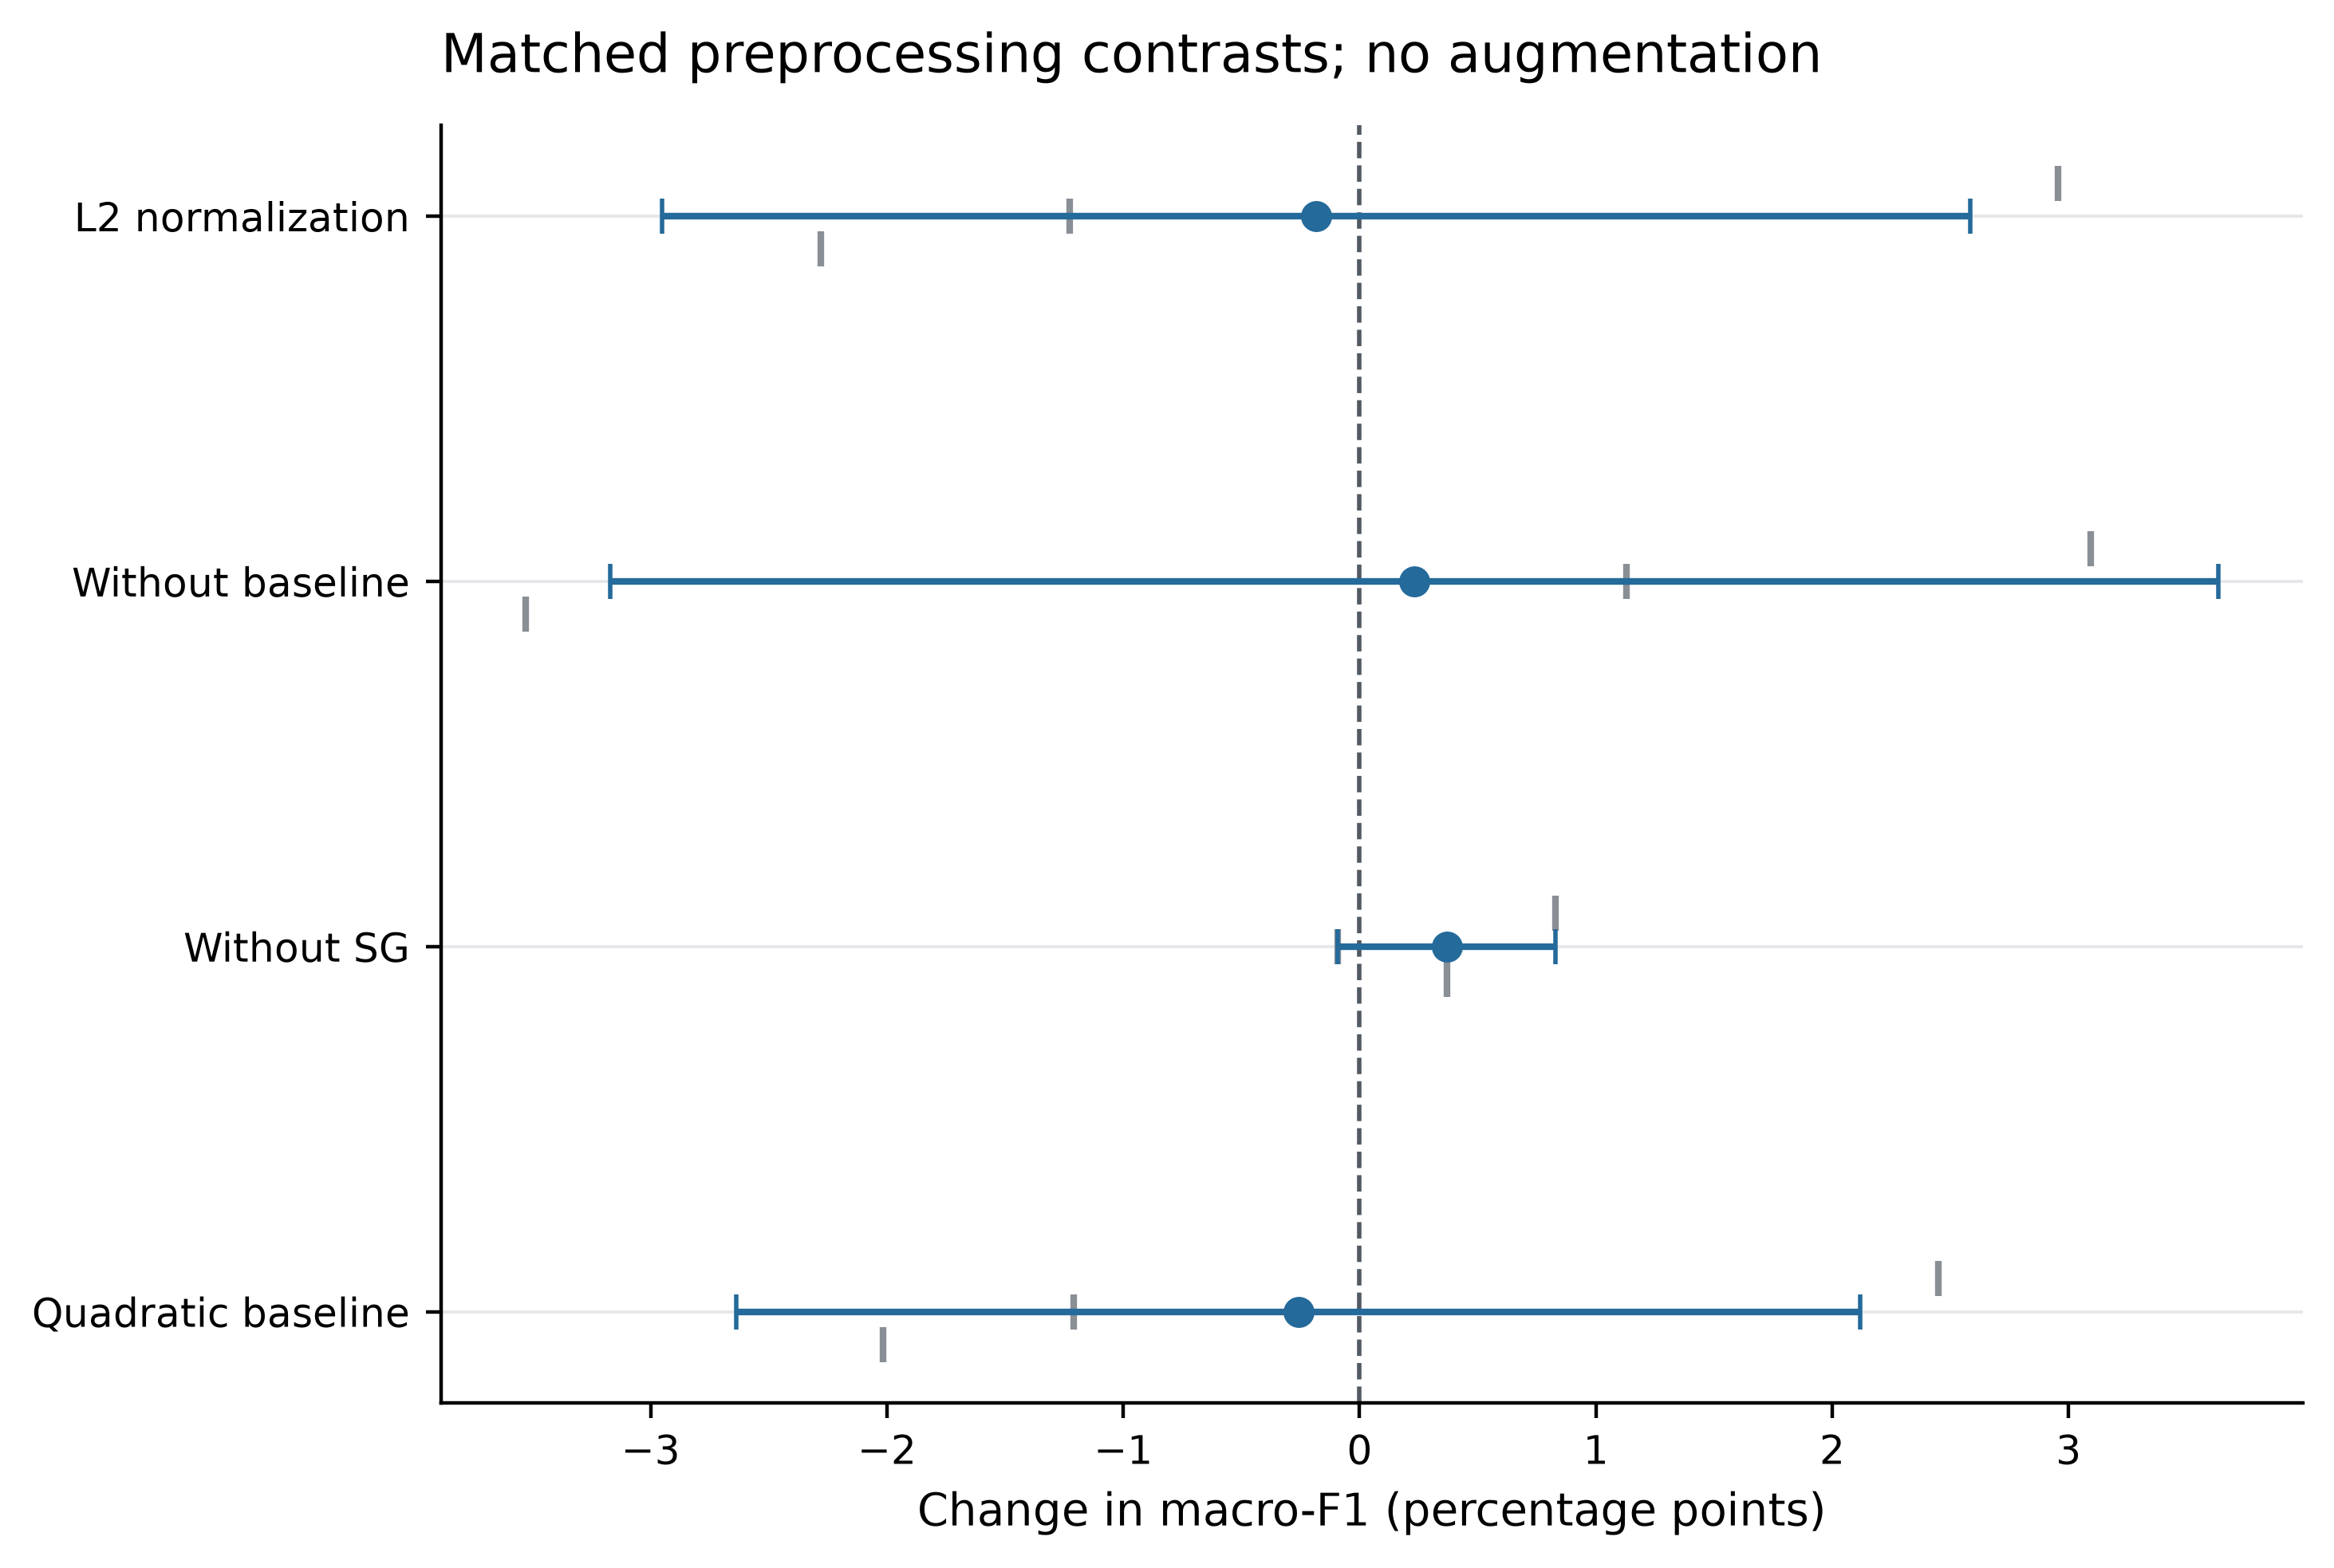

In [12]:
display(Image(filename=str(ROOT / 'extension_study/results/summary/figures/preprocessing_paired.png'), width=1050))

### 训练图规模与性能

按图嵌套选取约60%、80%、100%内训练map，所有水平覆盖12类；内验证和外评价图不变。各折实际比例因向上取整不同，100%复用核心CNN，不重复计一次新训练。

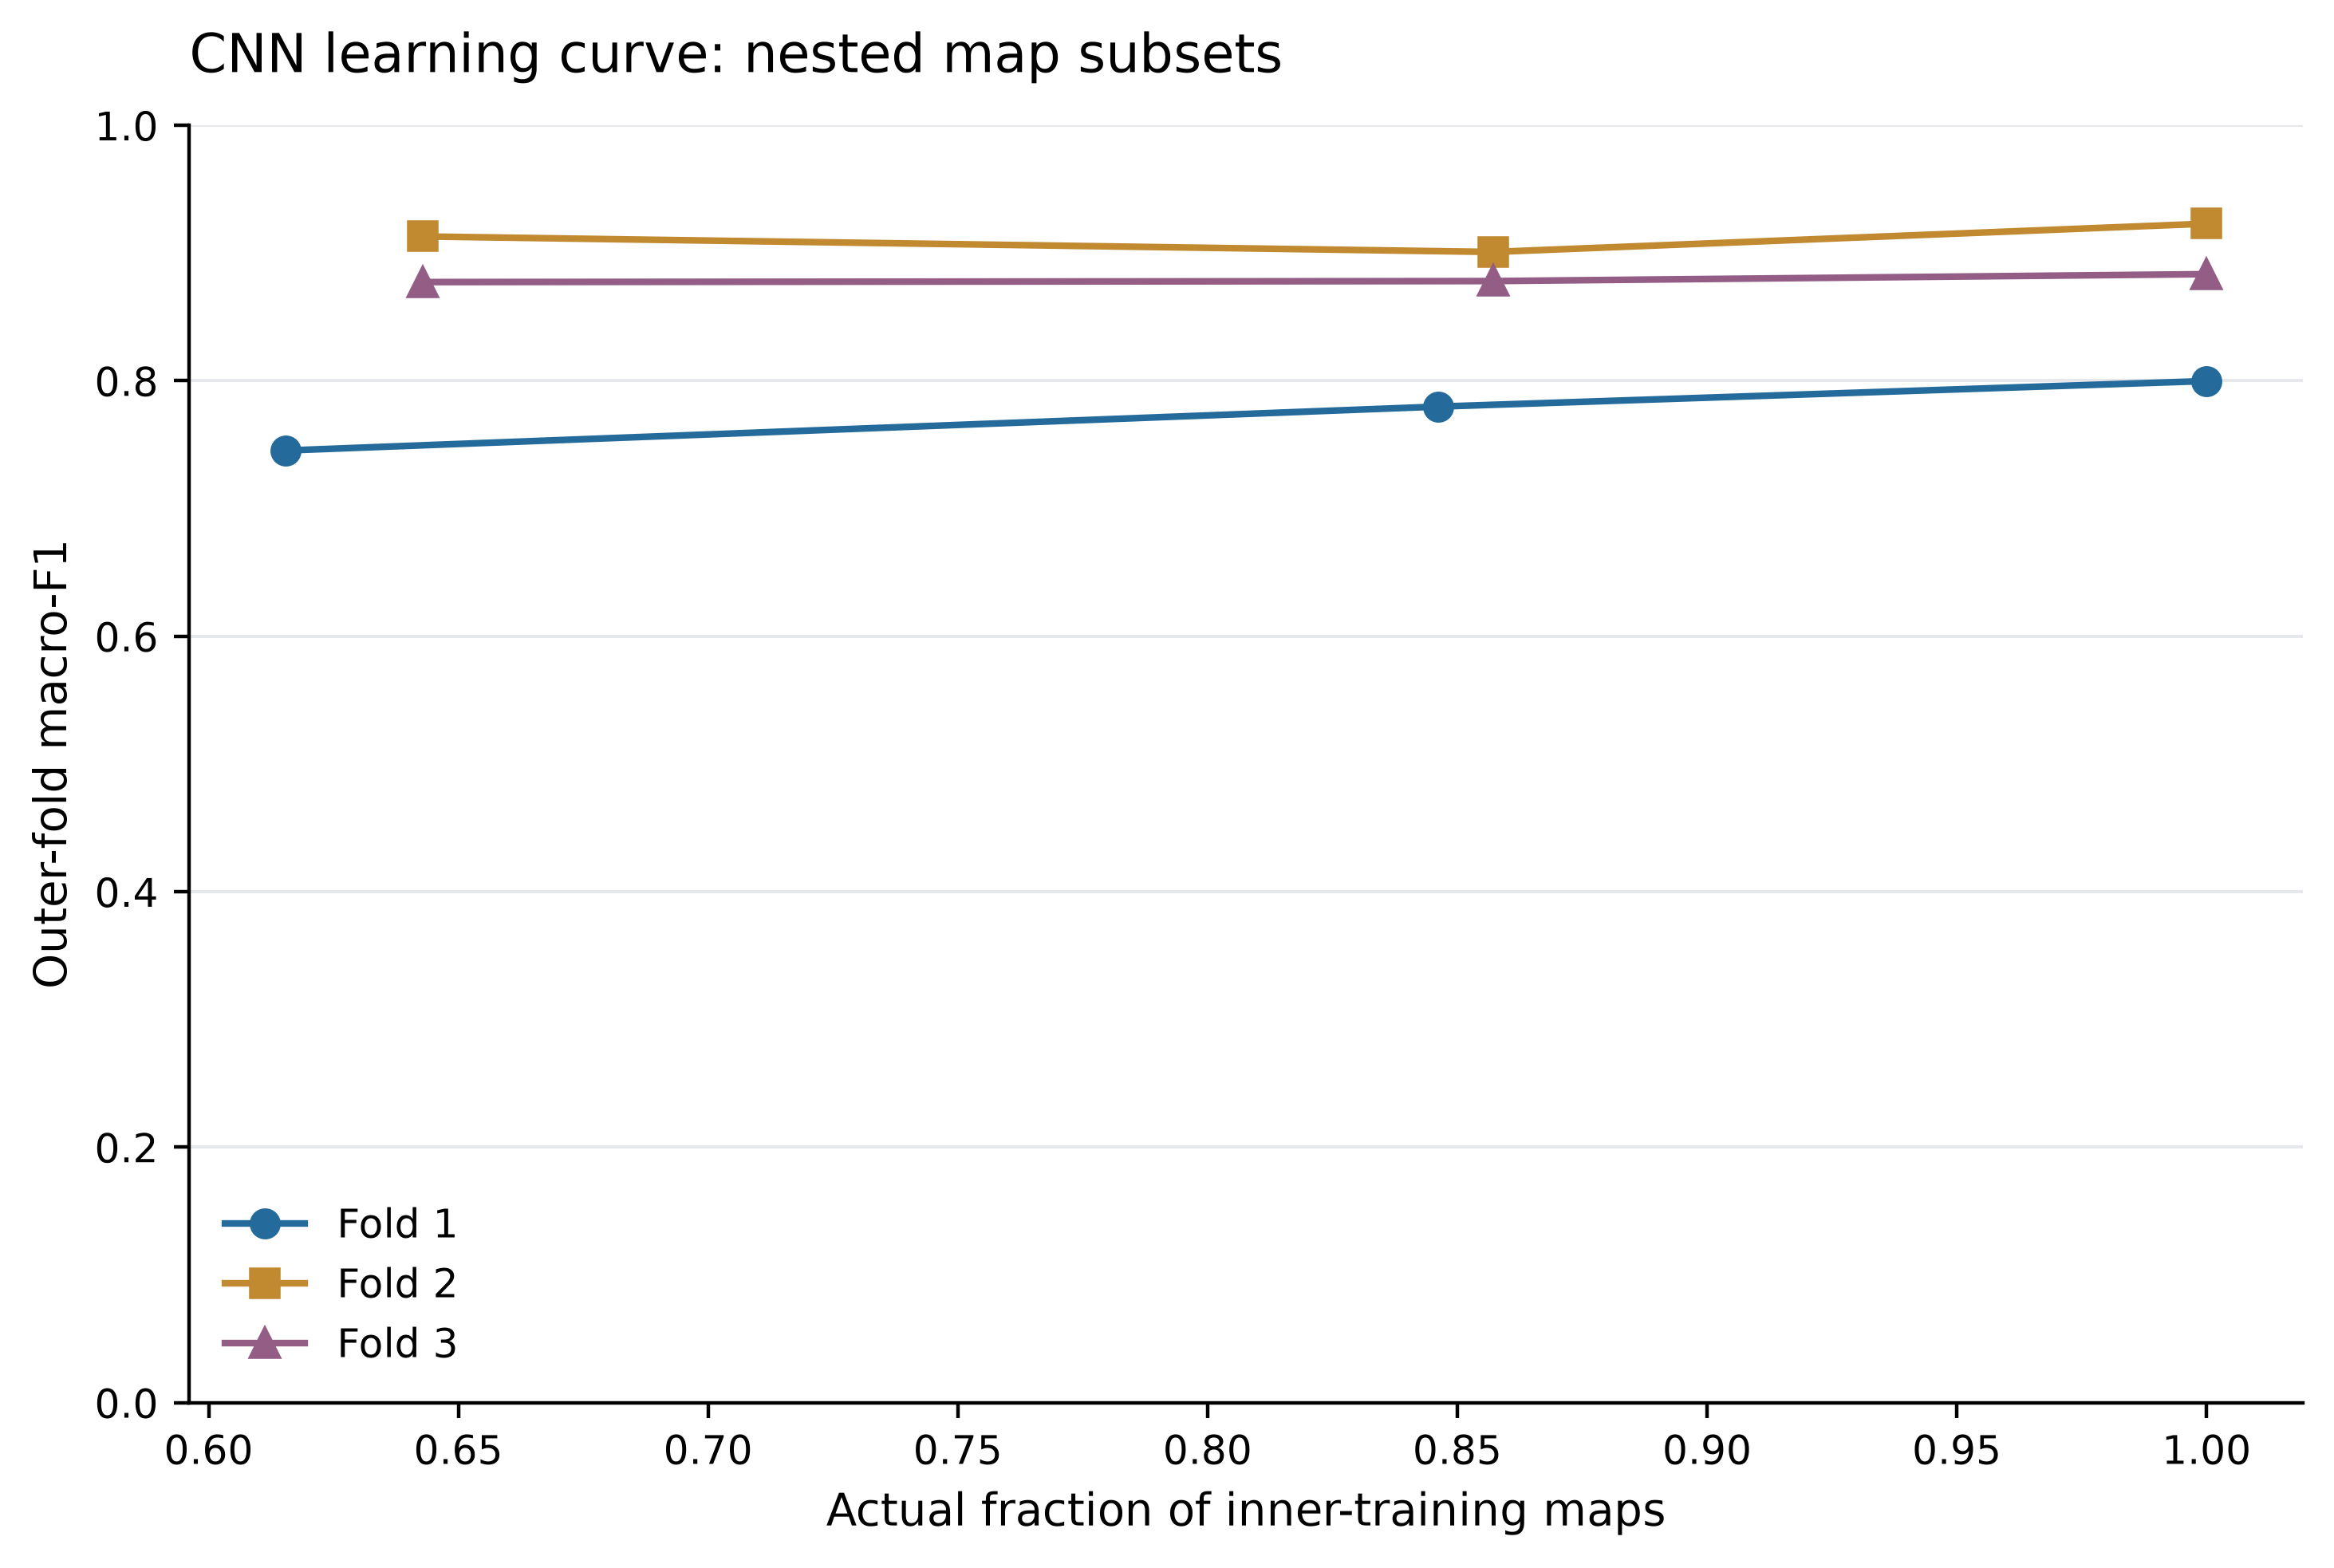

In [13]:
display(Image(filename=str(ROOT / 'extension_study/results/summary/figures/learning_curve_maps.png'), width=1050))

In [14]:
display(pd.read_csv(STUDY/'protocol/learning_curve_counts.csv'))
curve = pd.read_csv(SUMMARY/'learning_curve_fold_means.csv')
display(curve[['fold_id','level','map_count','pixels','actual_map_fraction','macro_f1_present']].round(4))

,fold_id,level,maps,pixels,target_fraction,actual_map_fraction,classes
0,1,maps60,8,6992,0.6,0.615385,12
1,1,maps80,11,8400,0.8,0.846154,12
2,1,maps100,13,10859,1.0,1.000000,12
3,2,maps60,9,7844,0.6,0.642857,12
4,2,maps80,12,9282,0.8,0.857143,12
5,2,maps100,14,11410,1.0,1.000000,12
6,3,maps60,9,9961,0.6,0.642857,12
7,3,maps80,12,11619,0.8,0.857143,12
8,3,maps100,14,13458,1.0,1.000000,12


,fold_id,level,map_count,pixels,actual_map_fraction,macro_f1_present
0,1,maps100,13,10859,1.0000,0.7997
1,2,maps100,14,11410,1.0000,0.9229
2,3,maps100,14,13458,1.0000,0.8834
3,1,maps60,8,6992,0.6154,0.7453
4,2,maps60,9,7844,0.6429,0.9129
5,3,maps60,9,9961,0.6429,0.8772
6,1,maps80,11,8400,0.8462,0.7797
7,2,maps80,12,9282,0.8571,0.9008
8,3,maps80,12,11619,0.8571,0.8780


## 6．科学解释、局限、结论与分工（8:15–10:00）

首轮测试中，简单PCA＋SVM并未被增强CNN稳定超越；复杂模型需要在严格隔离评价中证明收益。
扩展结果展示了在共同12类开发图和冻结训练策略下，架构、表示、增强及训练图规模的实际影响；它不能补救首轮稀缺类别，
也不能把新增较高分数移用为原15类六图测试性能。

仍需注意：图数有限、各折训练部分重叠；不同map可能共享原始材料；PC/PU/Sil在扩展中排除；源标签和采集条件尚未独立复核；
缺少新仪器、独立材料标本与未知类别评价。真实应用需要新的、可追踪样本及锁定的外部测试集。

| 成员 | 学号 | 本人实际完成与复核内容 | 展示或答问任务 |
| --- | --- | --- | --- |
| 待真实填写 | 待填 | 待本人填写 | 待填 |
| 待真实填写 | 待填 | 待本人填写 | 待填 |
| 第三人如有 | 待填 | 待本人填写 | 待填 |

课程要求2–3人，每人参与实质工作、理解全流程并参与展示或答问。代码、分析与初稿使用AI辅助，不能将自动完成的工作虚构为某位成员亲自完成。

## 附录A．误差、训练、扰动与校准（问答查阅）

这些分析都来自冻结预测或已经锁定权重后的开发外折评价。误差描述用于说明范围，不再据此改配置。

### 首轮15类混淆矩阵

低召回的PC、PU和PP应结合原谱和来源进一步复核，标签噪声与条件变化仍是解释假设。

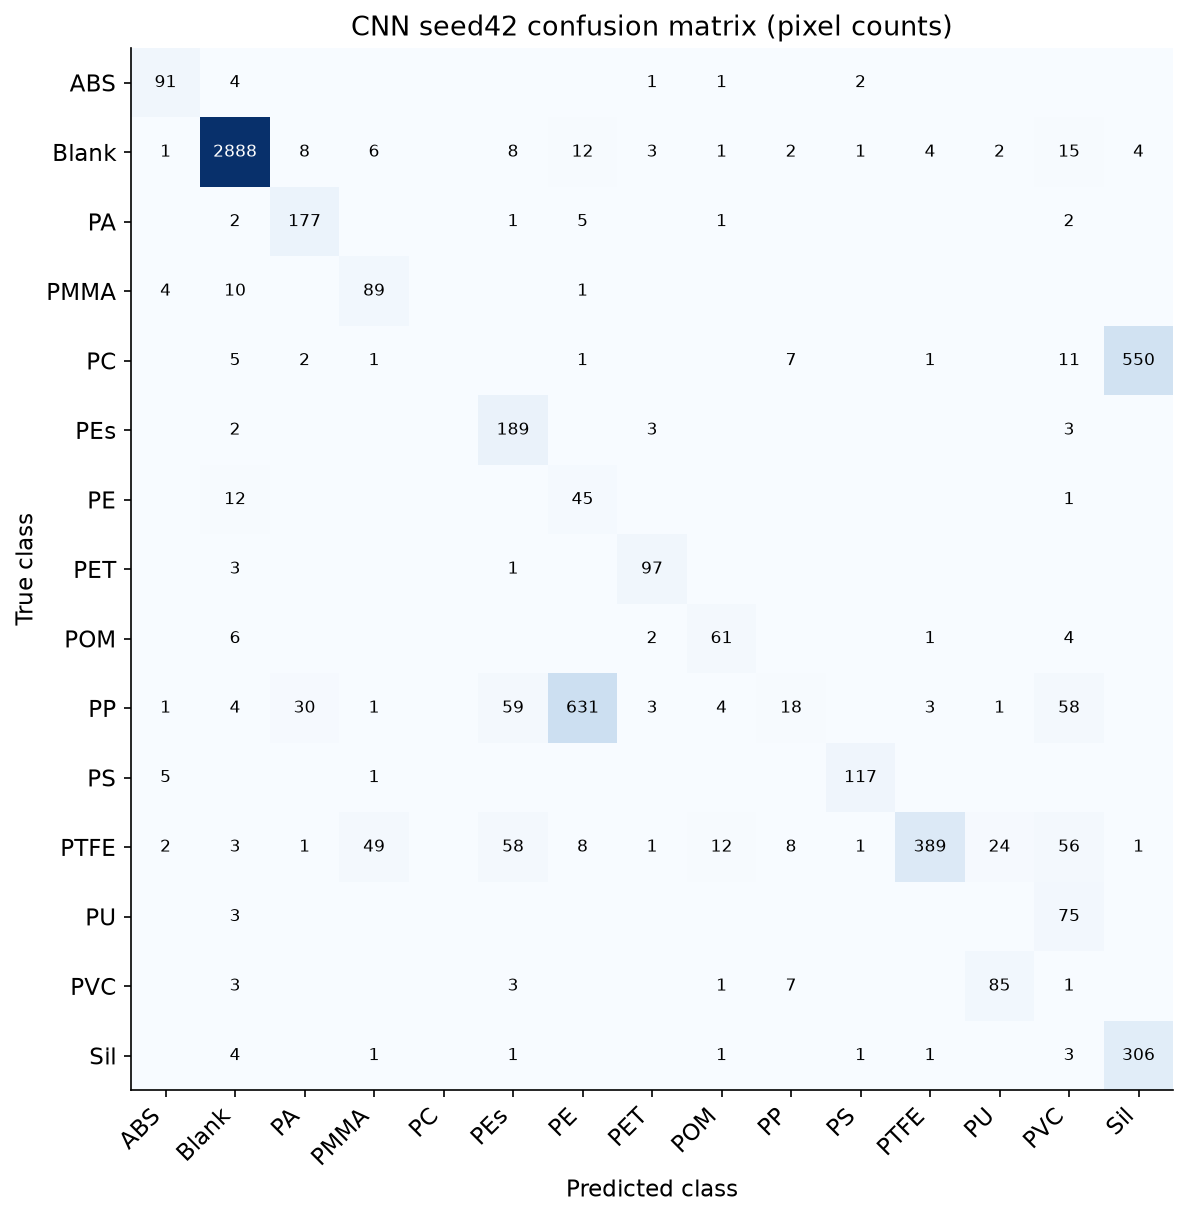

In [15]:
display(Image(filename=str(ROOT / 'results/final_test/figures/02_confusion_matrix.png'), width=1050))

### 首轮训练与13类验证轨迹

最佳epoch仅根据验证13类宏F1选择；原测试集从未用于早停。

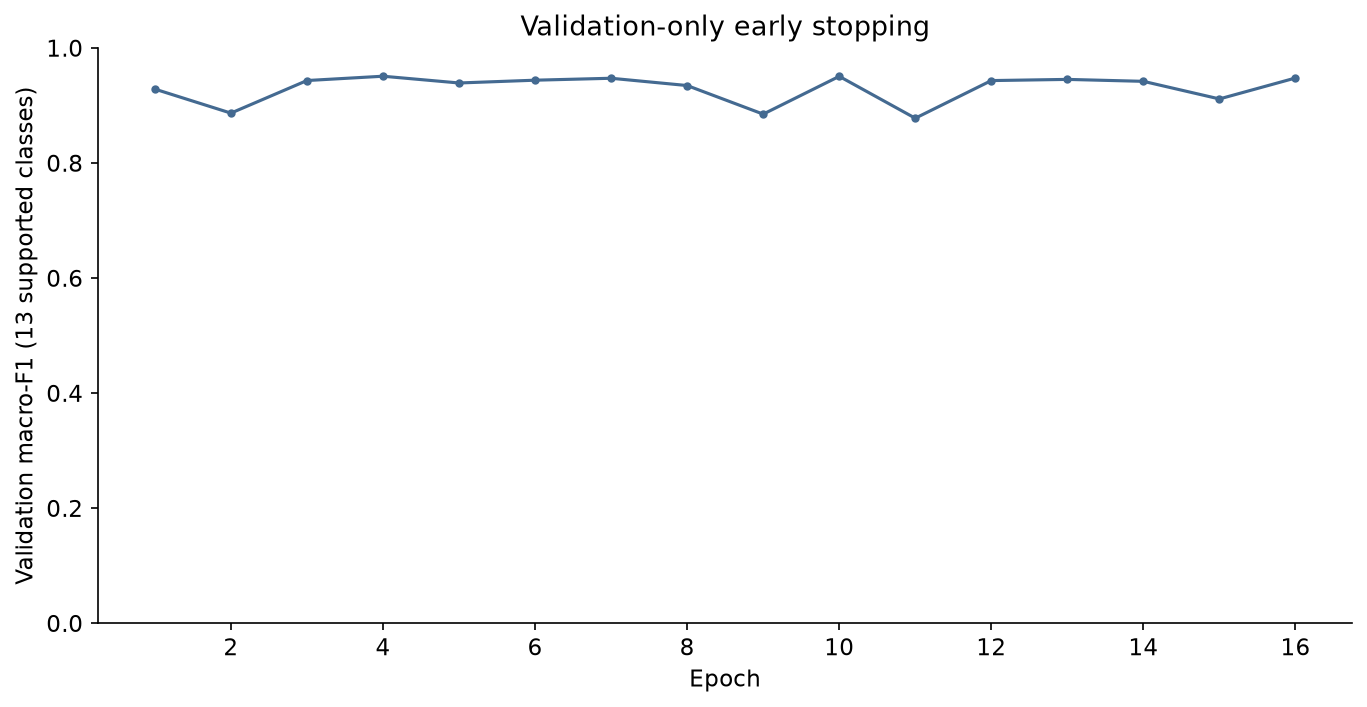

In [16]:
display(Image(filename=str(ROOT / 'results/final_test/figures/03_training_curve.png'), width=1050))

### 首轮基线内验证选型（13类，不是正式测试性能）

,model,macro_f1_present
0,cosine_centroid,0.7855
1,pca64_linear_svm_C0.1,0.9655
2,pca64_linear_svm_C1.0,0.9613
3,pca64_linear_svm_C10.0,0.9582


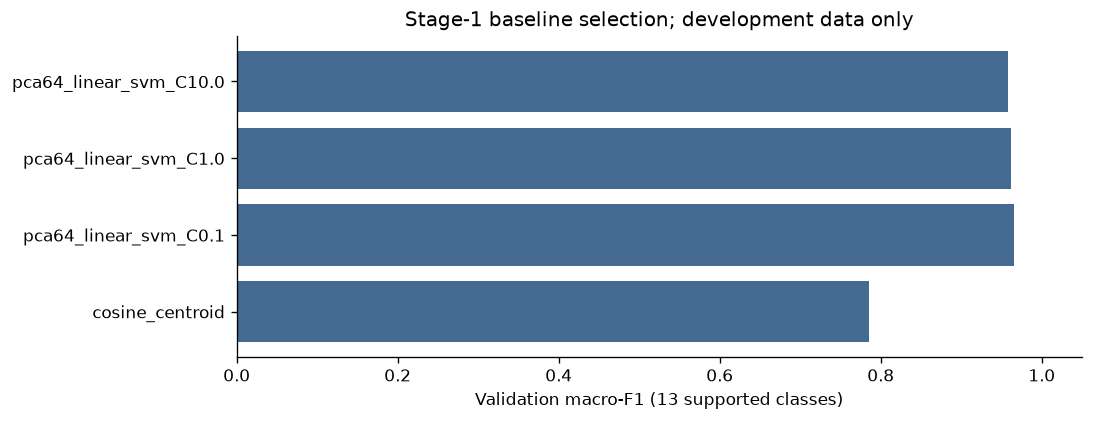

In [17]:
baseline_val = pd.read_csv(ROOT/'results/baselines/validation_comparison.csv')
display(baseline_val[['model','macro_f1_present']].round(4))
fig,ax = plt.subplots(figsize=(9,3.4),layout='constrained')
ax.barh(baseline_val.model,baseline_val.macro_f1_present,color='#446A91')
ax.set(xlim=(0,1.05),xlabel='Validation macro-F1 (13 supported classes)',title='Stage-1 baseline selection; development data only')
plt.show()

### 实际训练像素数学习曲线

训练图是控制的采样单位，像素数为随之改变的实际规模；增加像素不等于增加相同数量的独立材料。

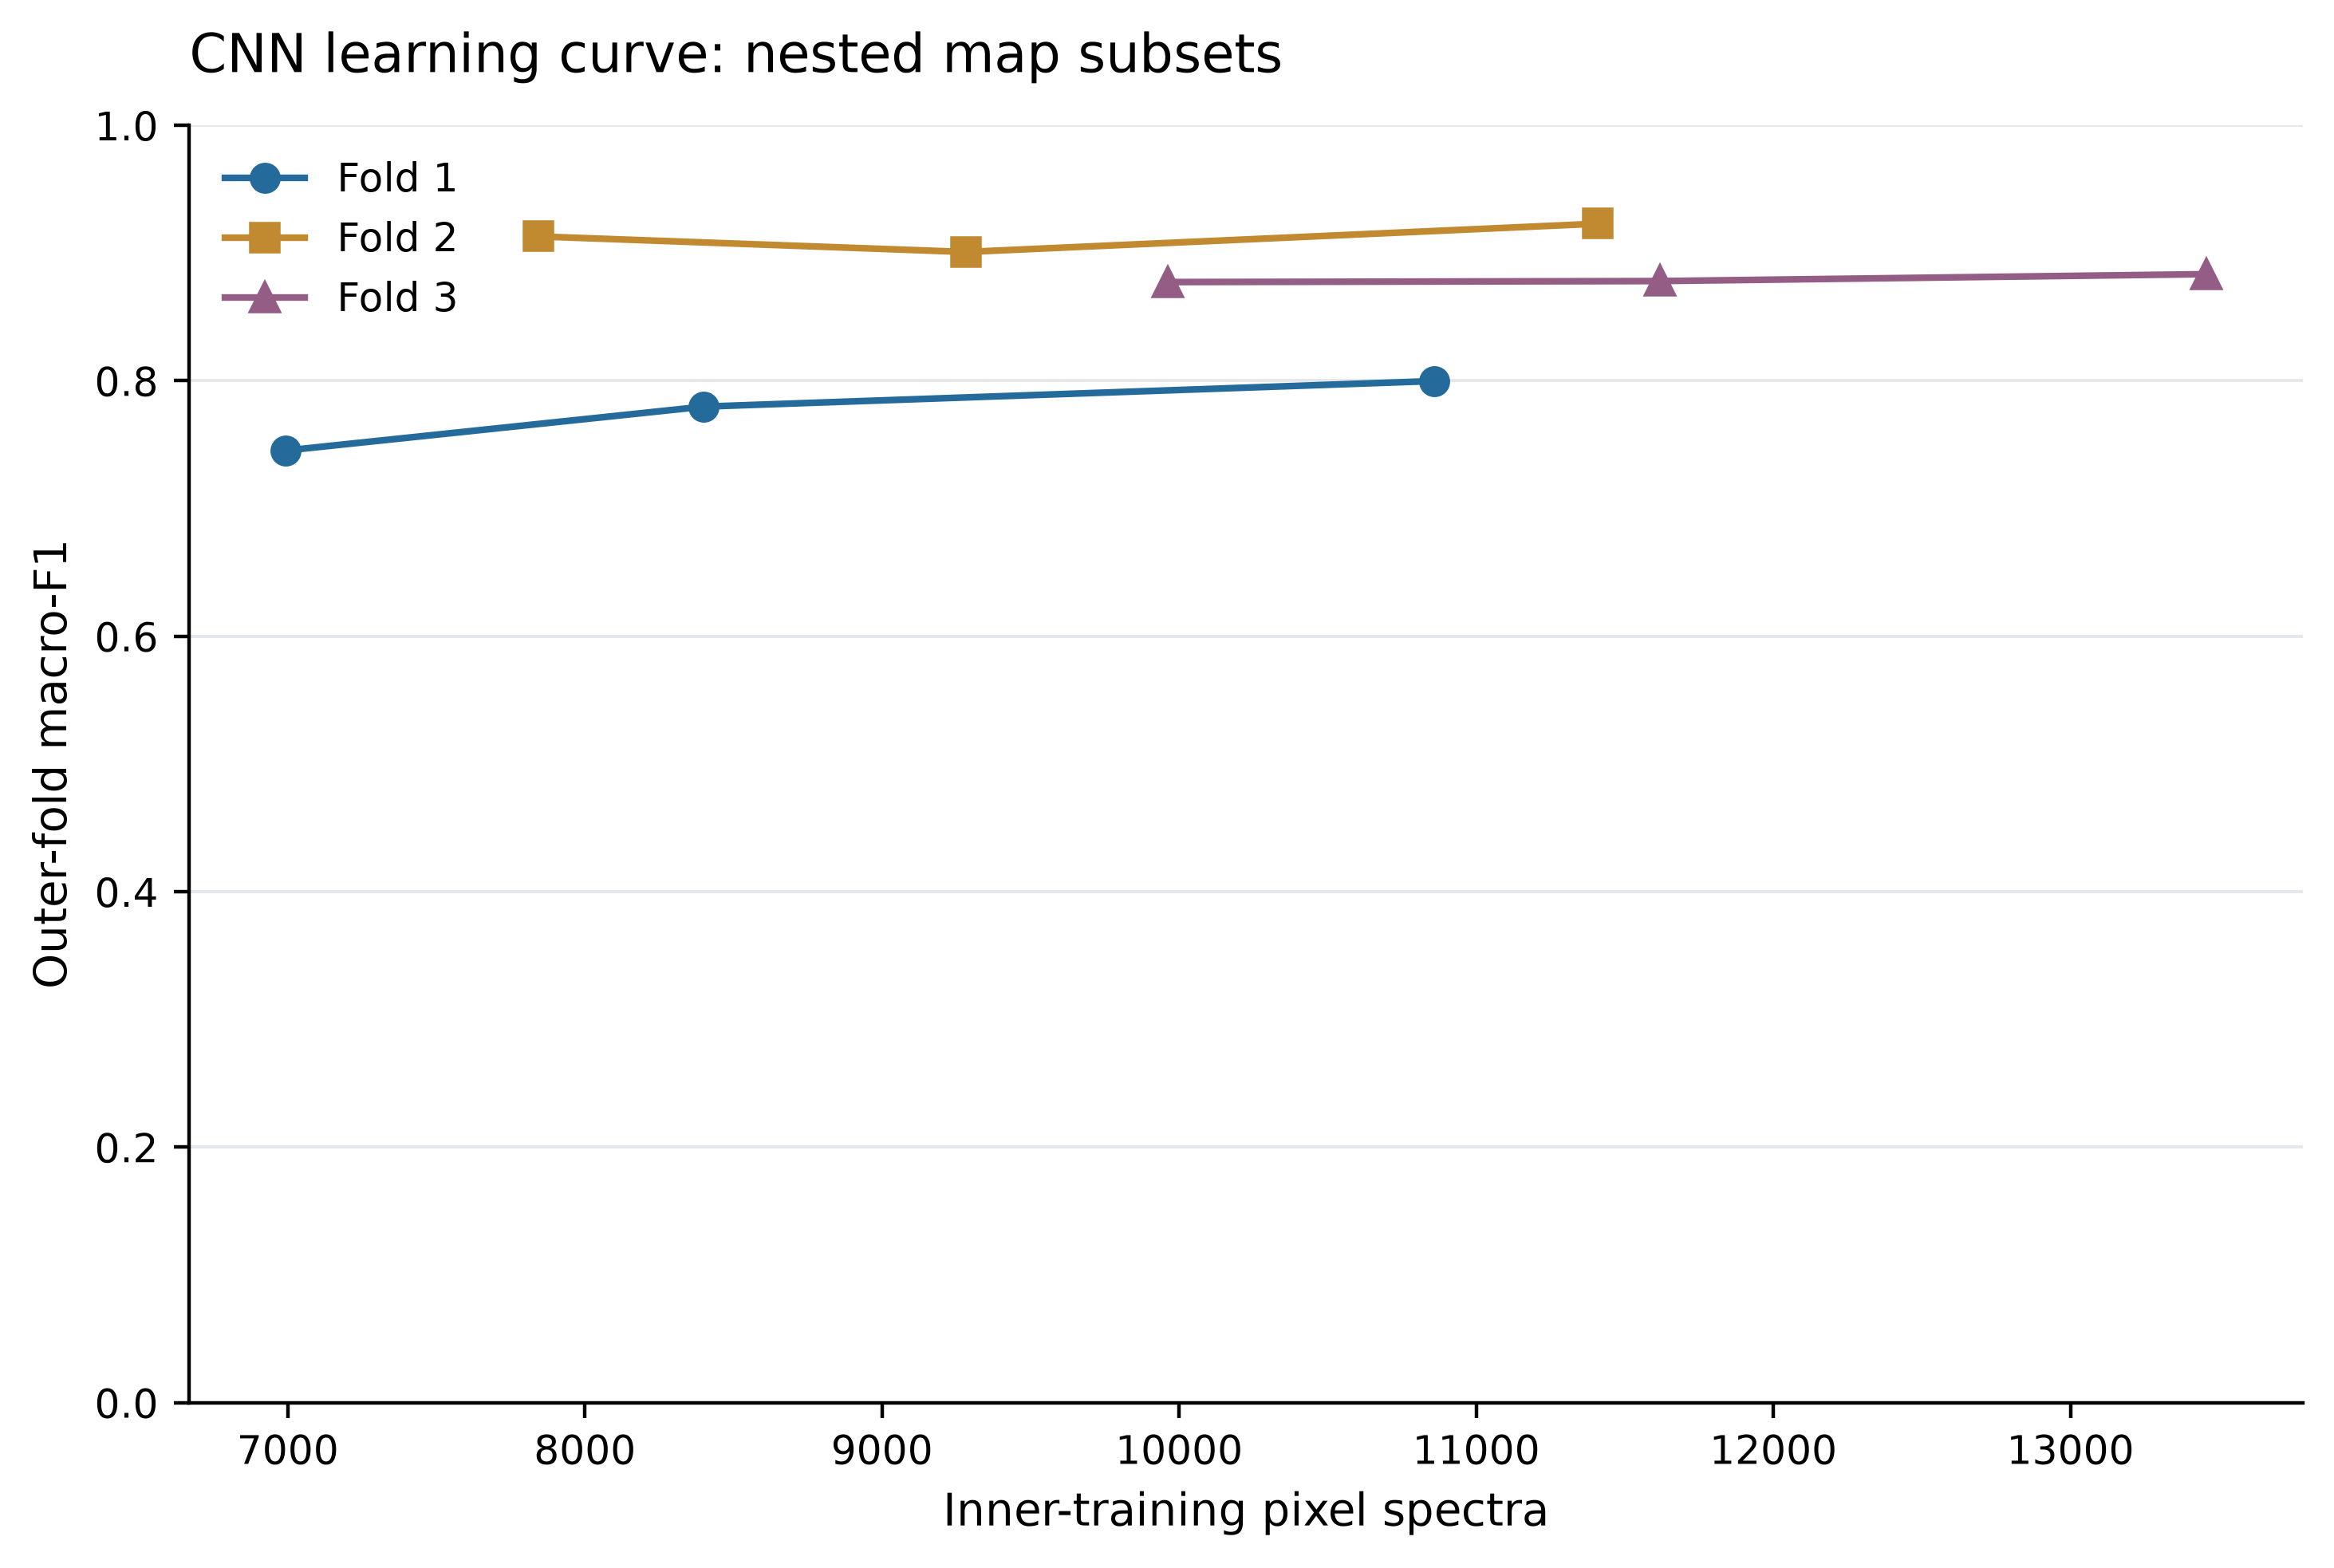

In [18]:
display(Image(filename=str(ROOT / 'extension_study/results/summary/figures/learning_curve_pixels.png'), width=1050))

### 模拟加噪敏感性

在SNV处理后输入上加标准差0/0.02/0.05/0.1/0.2的高斯噪声，不再SNV；同折同水平共享一个扰动实现。不是仪器信噪比标定或真实噪声外部验证。

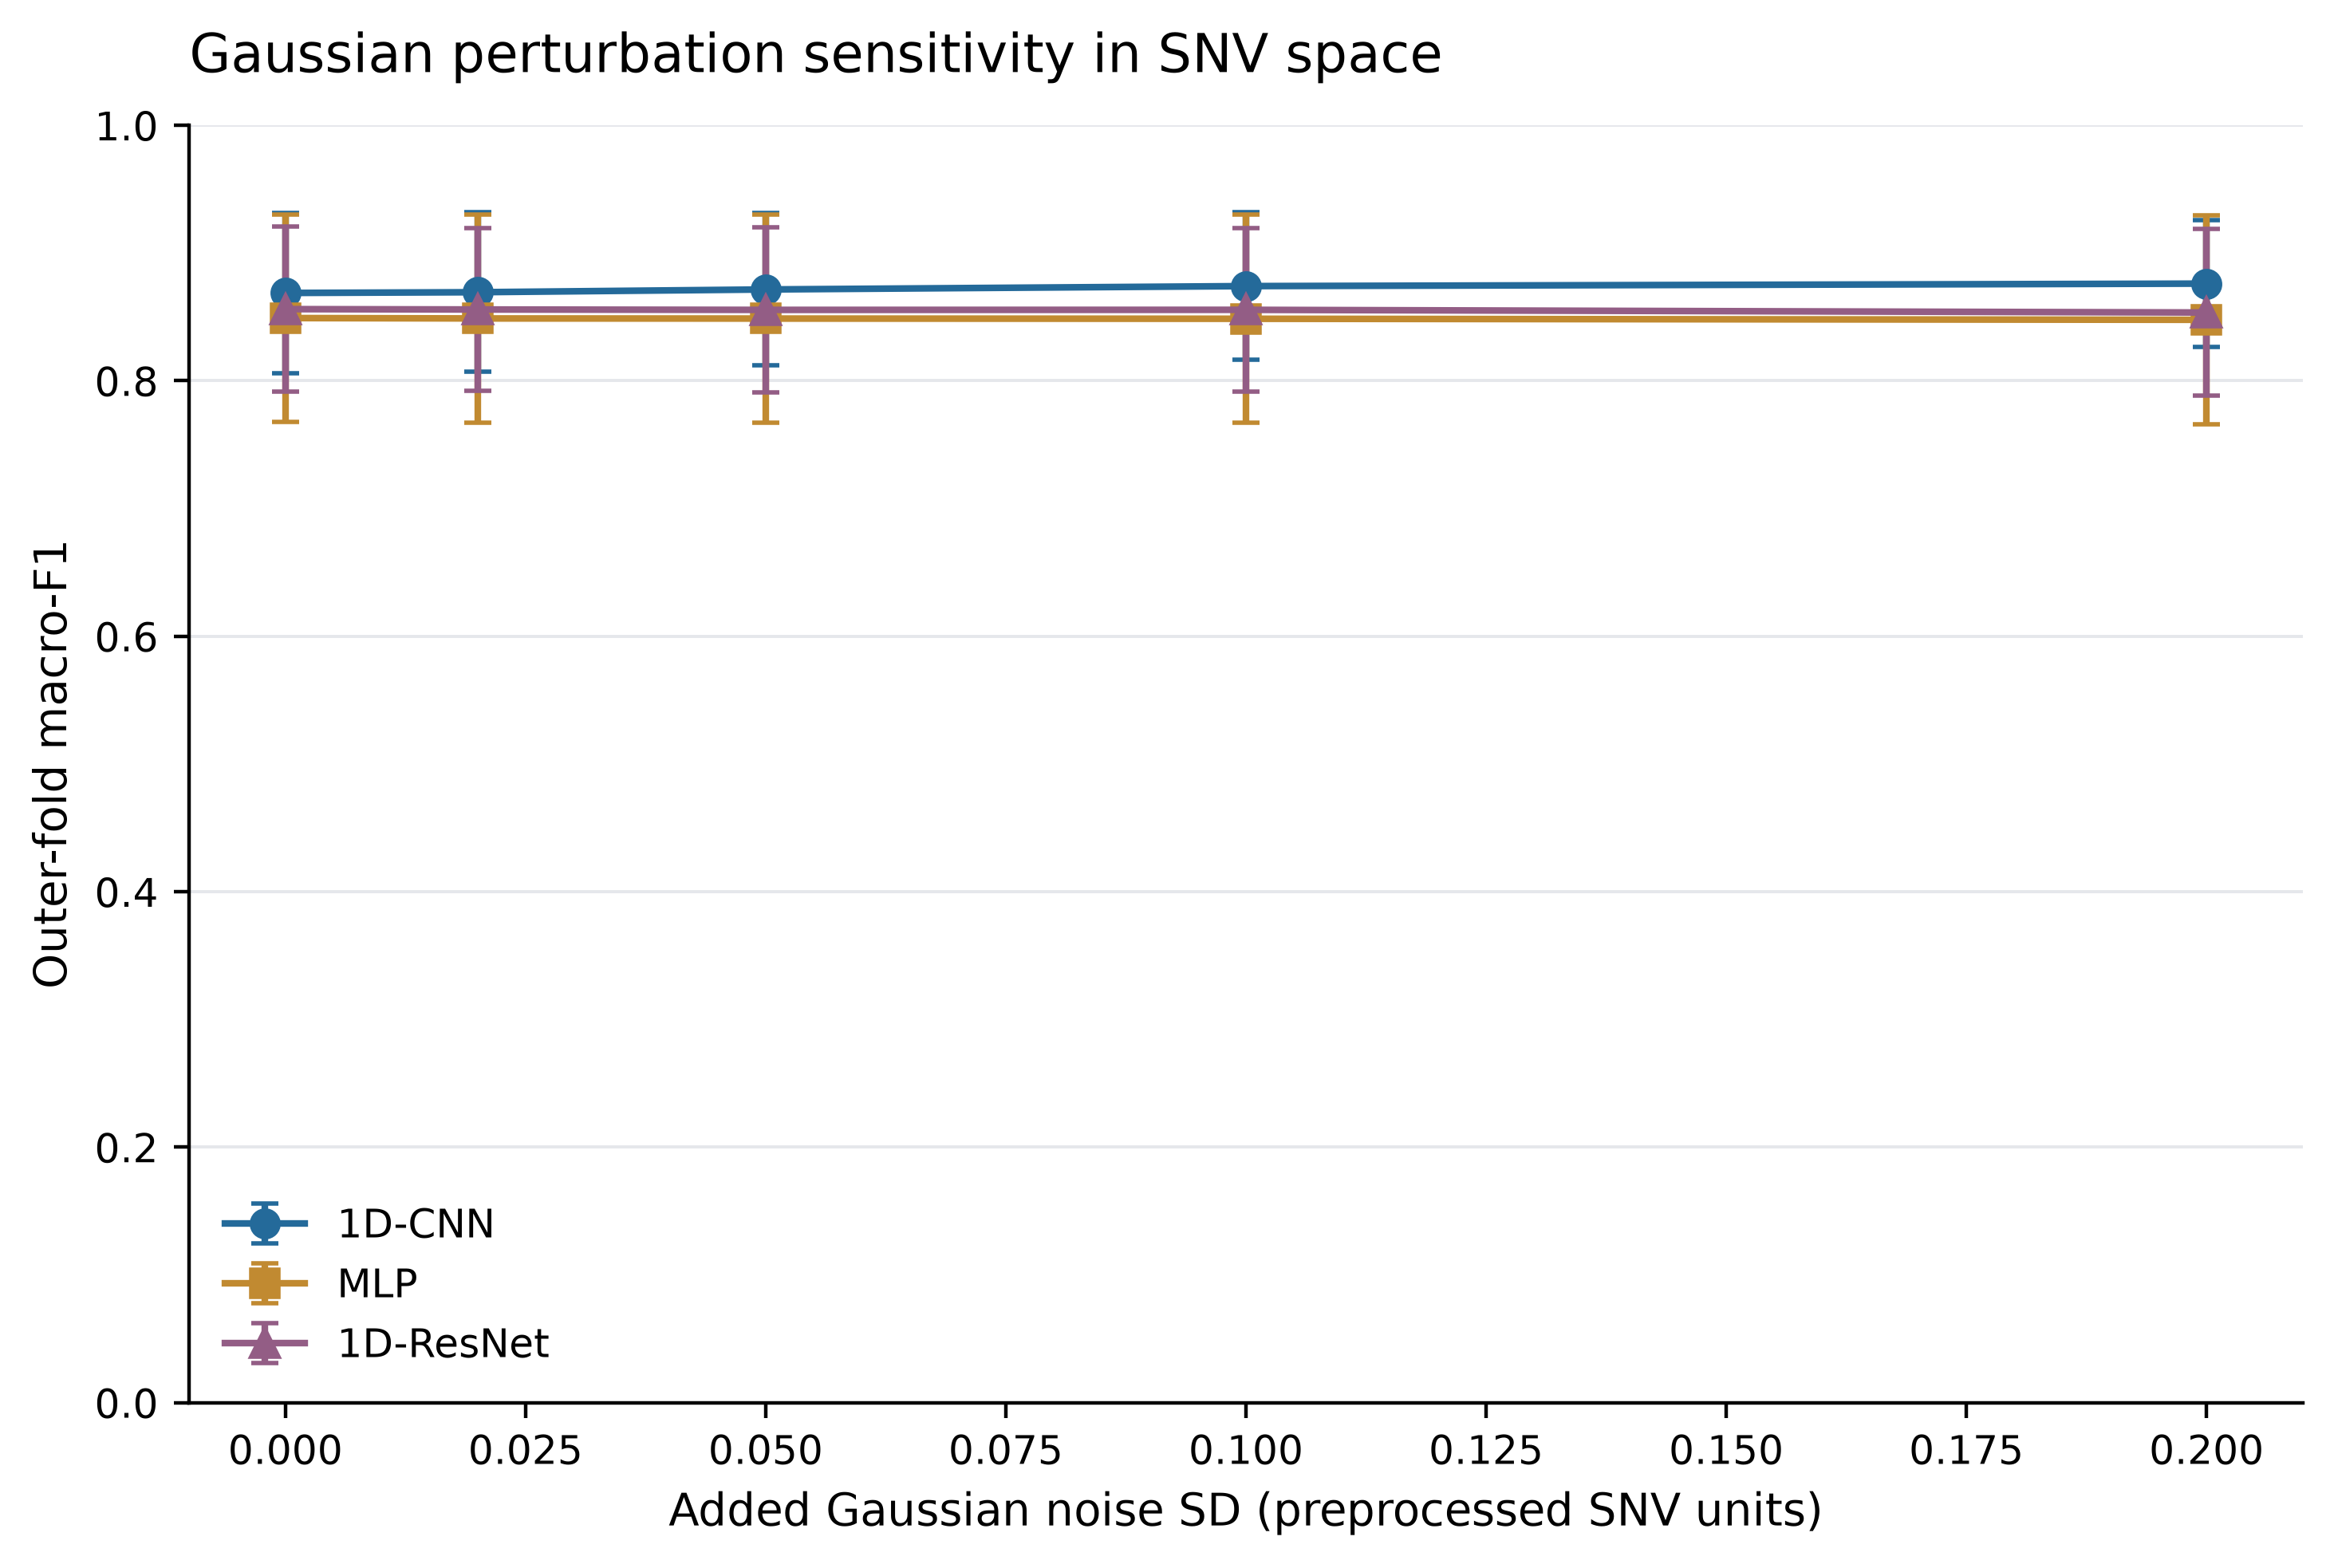

In [19]:
display(Image(filename=str(ROOT / 'extension_study/results/summary/figures/noise_robustness.png'), width=1050))

### 置信度校准误差

ECE采用10等宽置信度箱，数值更低表示此评价口径下更接近经验准确率；ECE受分箱方案和数据分布影响。未用外折拟合温度或阈值。

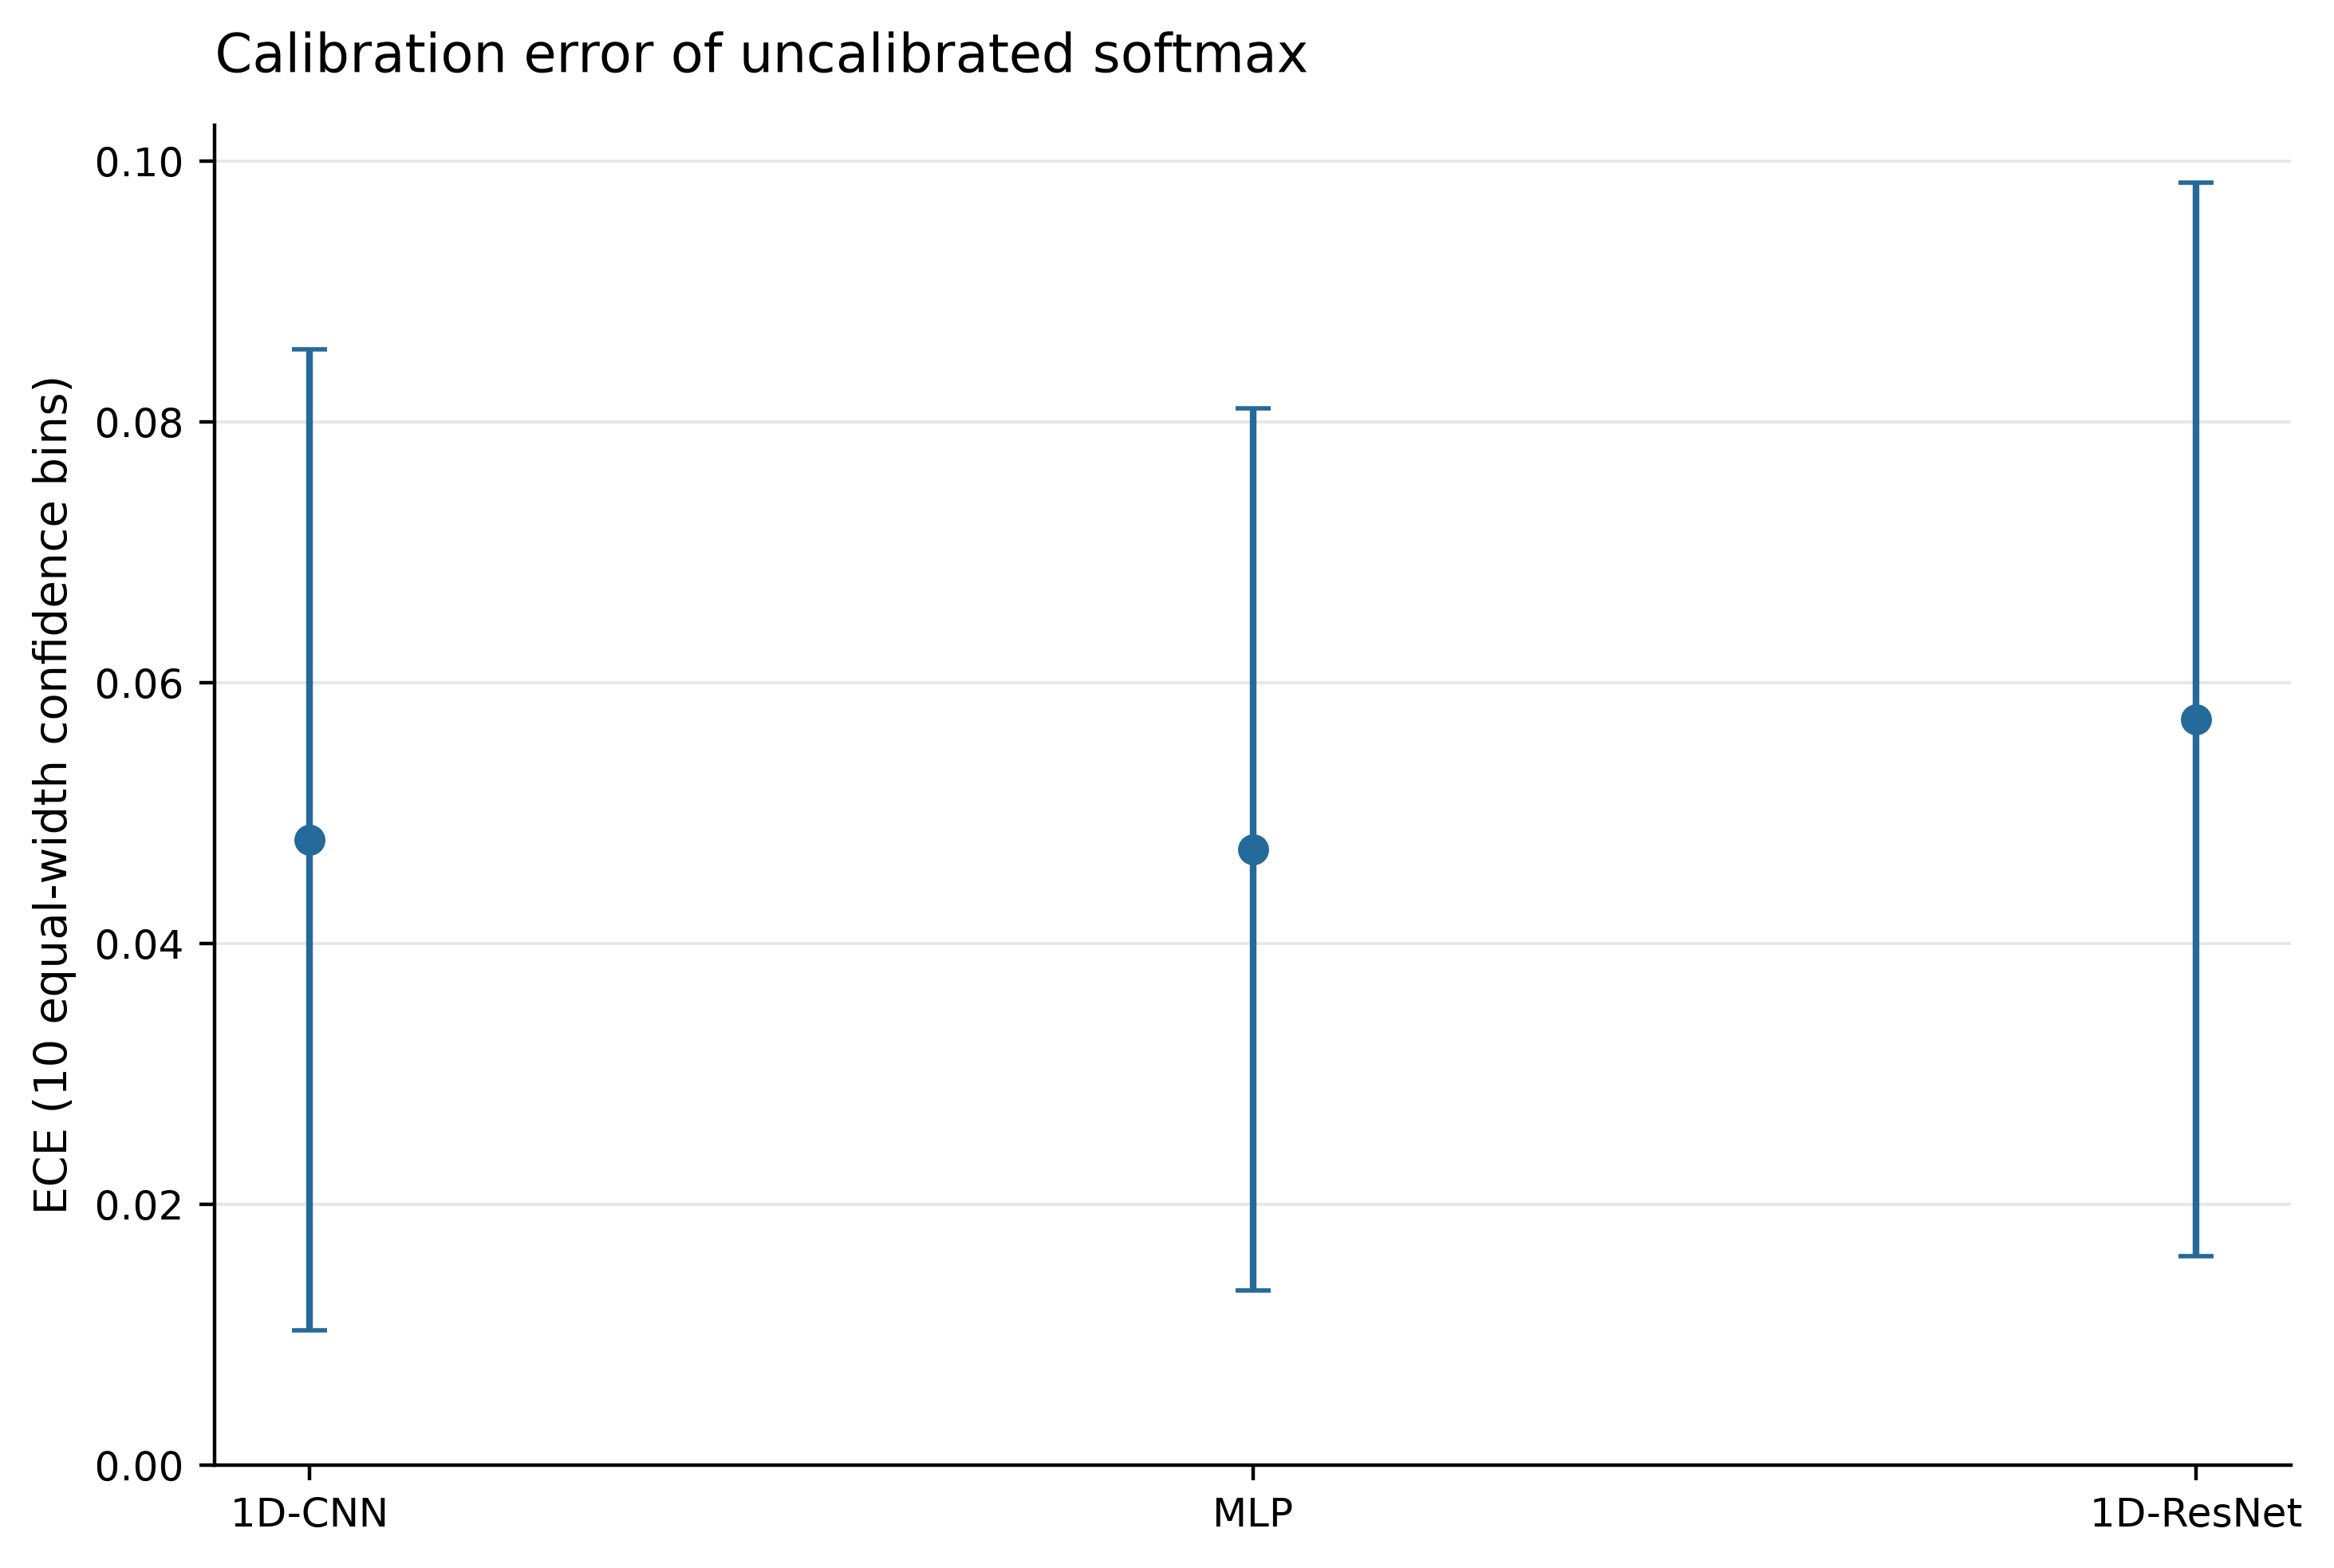

In [20]:
display(Image(filename=str(ROOT / 'extension_study/results/summary/figures/calibration_ece.png'), width=1050))

### 固定seed101的可靠性图

合并互斥外折像素且每个仅计一次；这是按像素汇集的诊断图，与三折平均指标的加权方式不同。

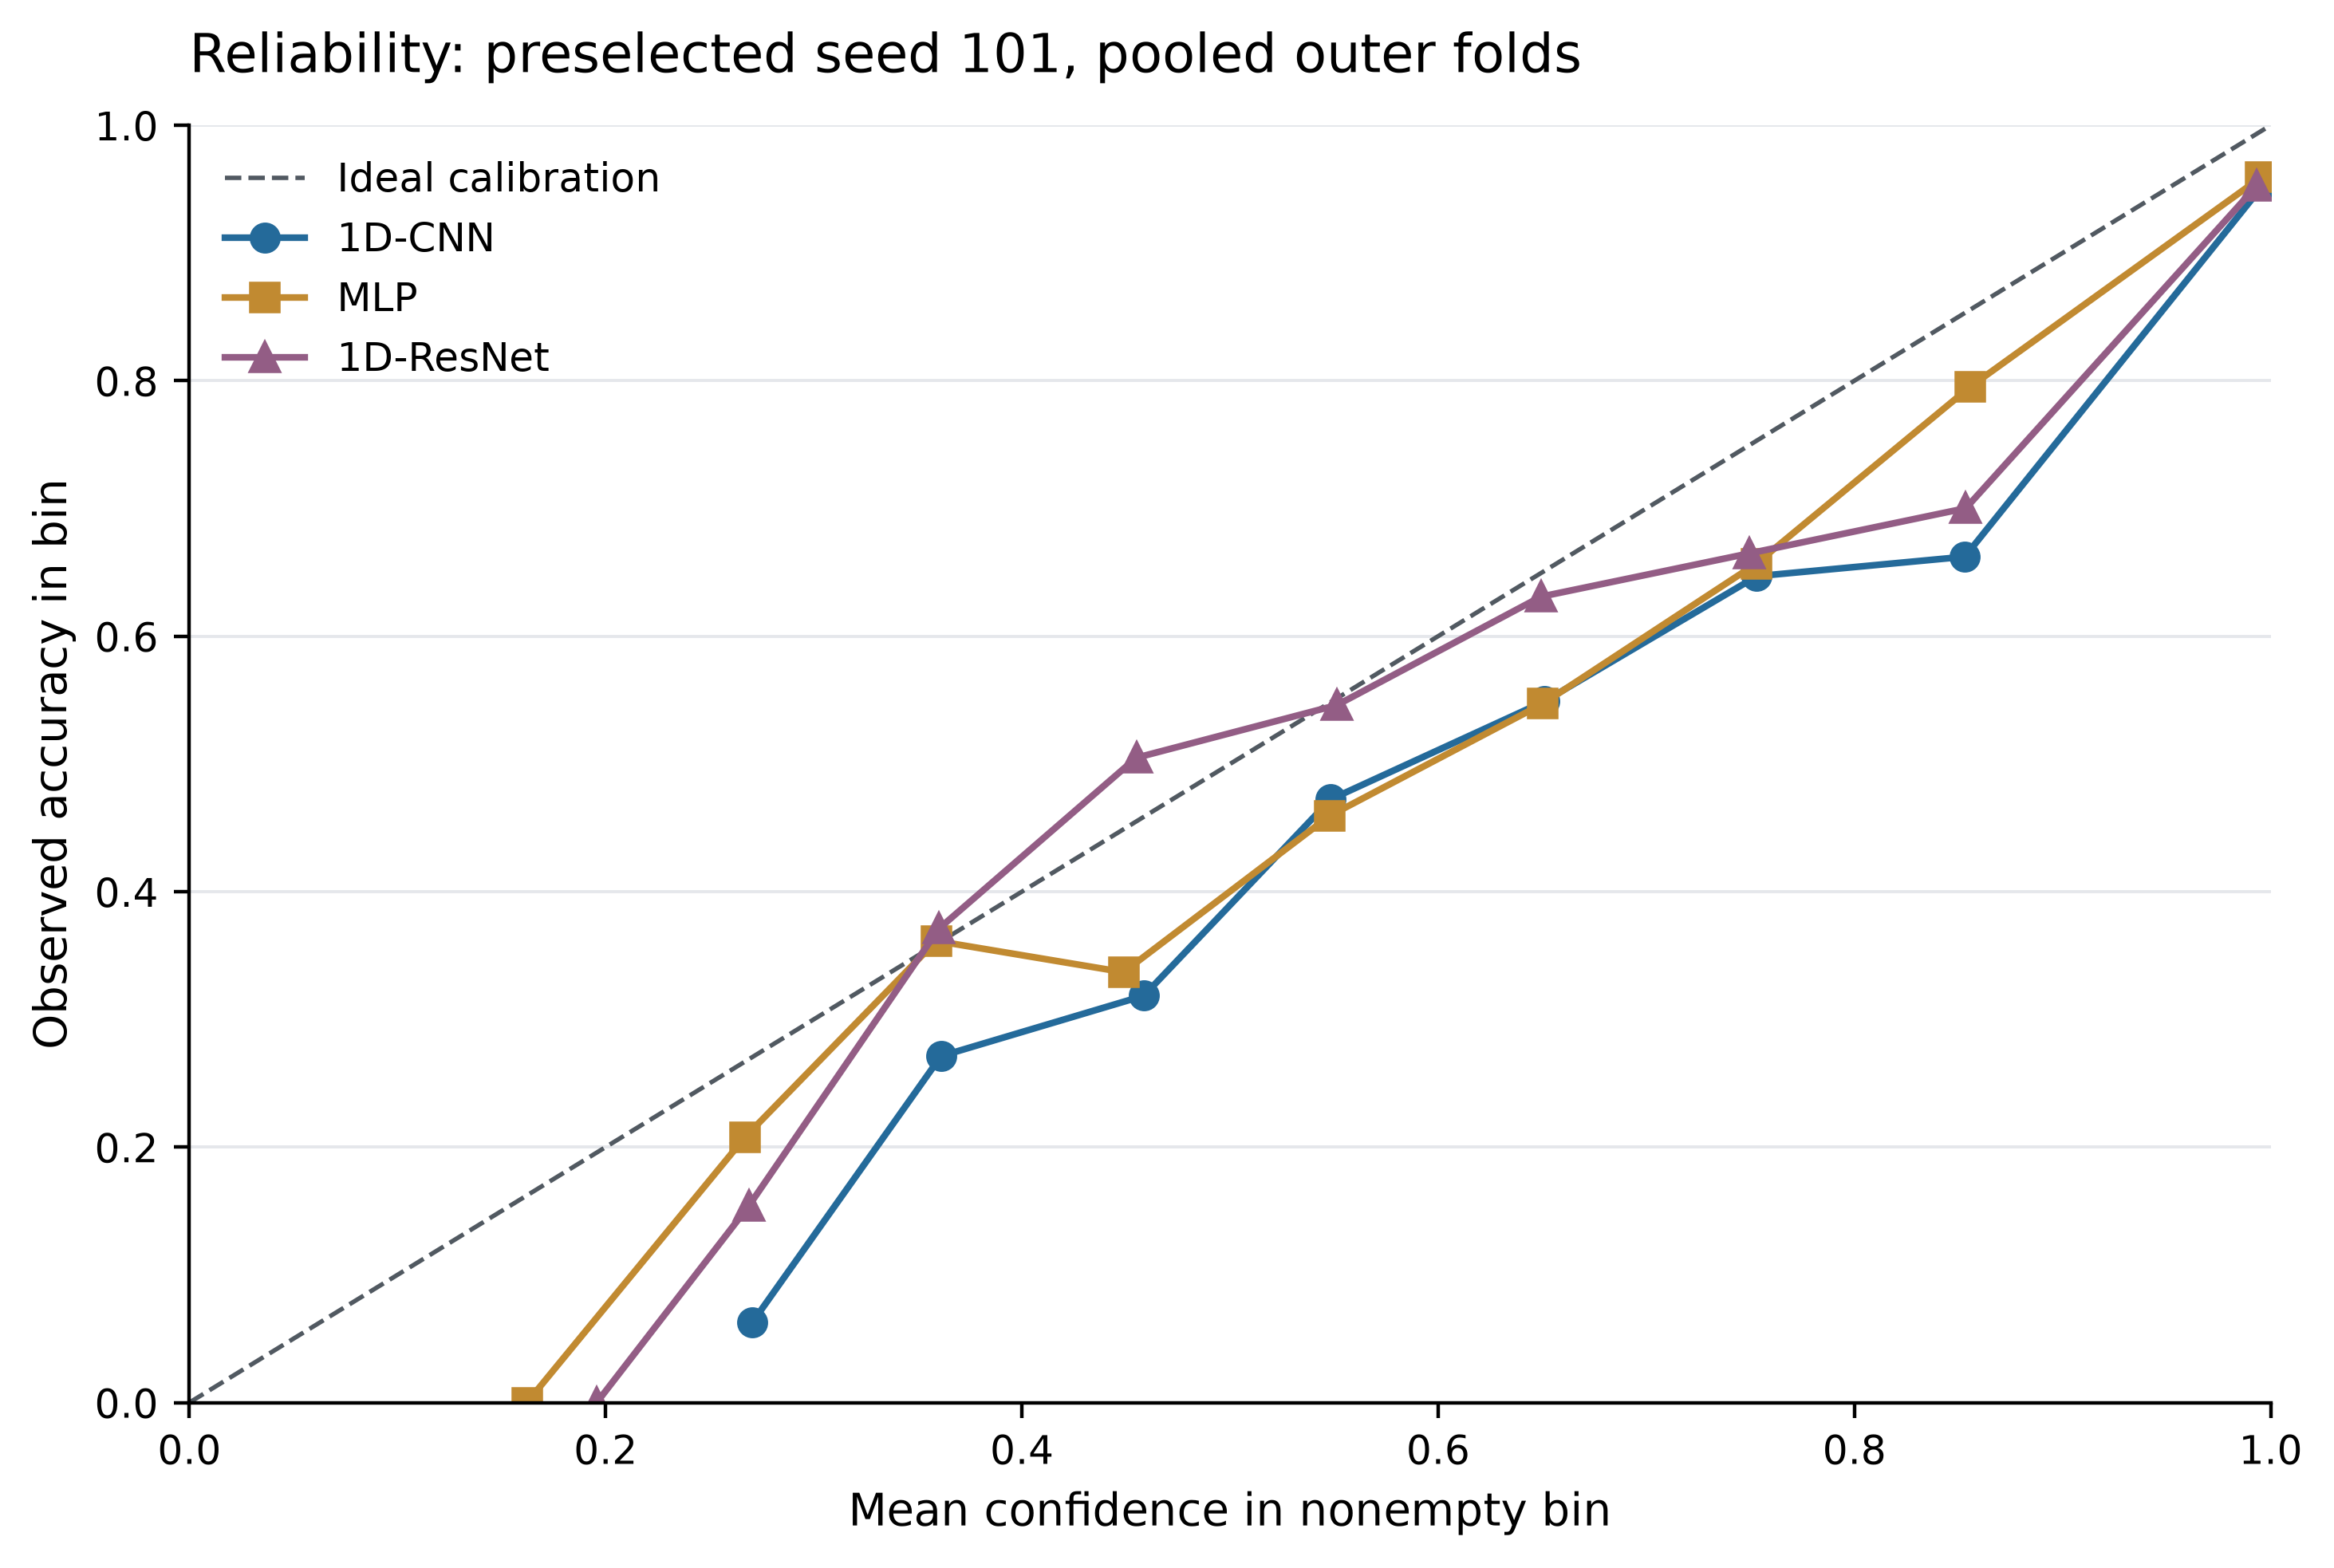

In [21]:
display(Image(filename=str(ROOT / 'extension_study/results/summary/figures/calibration_reliability.png'), width=1050))

In [22]:
calibration = pd.read_csv(SUMMARY/'calibration_summary.csv')
display(calibration[calibration.condition.str.startswith('architecture:')].round(4))
class_scores = pd.read_csv(SUMMARY/'class_summary.csv')
cnn_classes = class_scores[class_scores.condition=='architecture:cnn'].sort_values('f1_mean')
display(cnn_classes[['label','precision_mean','recall_mean','f1_mean','f1_fold_sd']].round(4))

,condition,n_complete_folds,complete,ece_10_bins_mean,ece_10_bins_fold_sd,negative_log_likelihood_mean,negative_log_likelihood_fold_sd,multiclass_brier_mean,multiclass_brier_fold_sd
0,architecture:cnn,3,True,0.0480,0.0376,0.6191,0.3917,0.1304,0.0634
1,architecture:mlp,3,True,0.0472,0.0338,0.5365,0.3174,0.1390,0.0701
2,architecture:resnet,3,True,0.0572,0.0412,0.6522,0.3845,0.1482,0.0742


,label,precision_mean,recall_mean,f1_mean,f1_fold_sd
11,polyvinyl chloride,0.5149,0.5434,0.5107,0.4332
2,nylon,0.6393,0.7441,0.6294,0.2133
8,polypropylene,0.9060,0.8295,0.8535,0.1127
0,acrylonitrile butadiene styrene,0.9191,0.9021,0.9070,0.0527
3,poly (methyl methacrylate),0.8826,0.9390,0.9087,0.0028
9,polystyrene,0.8987,0.9528,0.9219,0.0216
5,polyethylene,0.9180,0.9525,0.9327,0.0136
4,polyester,0.9246,0.9511,0.9371,0.0115
6,polyethylene terephthalate,0.9549,0.9248,0.9389,0.0382
10,polytetrafluoroethylene,0.9696,0.9235,0.9424,0.0519


## 附录B．从保存预测重算指标（不重新测试或训练）

重算只读取既有预测文件，不加载原六图输入进行新模型预测，也不覆盖任何正式结果。
macro-F1平均评价集合有真值的类别；图等权宏F1先令每像素权重为本图像素数倒数，再计算加权混淆对应F1。

In [23]:
def recompute_metrics(truth,prediction,map_ids):
    truth = np.asarray(truth); prediction = np.asarray(prediction); map_ids = np.asarray(map_ids)
    present = np.unique(truth)
    unique,inverse,counts = np.unique(map_ids,return_inverse=True,return_counts=True)
    return {'accuracy':accuracy_score(truth,prediction),
            'macro_f1_present':f1_score(truth,prediction,labels=present,average='macro',zero_division=0),
            'balanced_accuracy':recall_score(truth,prediction,labels=present,average='macro',zero_division=0),
            'map_mean_accuracy':np.mean([np.mean(truth[map_ids==g]==prediction[map_ids==g]) for g in unique]),
            'map_equal_weight_macro_f1':f1_score(truth,prediction,labels=present,average='macro',
                                                 sample_weight=1/counts[inverse],zero_division=0)}
saved = pd.read_csv(ROOT/'results/final_test/pixel_predictions.csv')
for row in formal.itertuples(index=False):
    recalculated = recompute_metrics(saved.true_label,saved[row.model],saved.map_id)
    for key,value in recalculated.items():
        assert np.isclose(value,getattr(row,key),atol=1e-10), (row.model,key)
extension_checks = []
for config in plan['configs']:
    directory = STUDY/'results/runs'/config['run_id']
    frame = pd.read_csv(directory/'outer_predictions.csv')
    assert set(frame.map_id).isdisjoint(study_protocol['original_test_maps_excluded'])
    result = recompute_metrics(frame.true_label,frame.predicted_label,frame.map_id)
    stored = load_json(directory/'outer_metrics.json')
    delta = max(abs(value-stored[key]) for key,value in result.items())
    assert delta<1e-10
    extension_checks.append(delta)
print('首轮6个模型的既有预测及扩展75个神经run指标复算通过；最大误差：',max(extension_checks))
print('包括9组基线的完整84组独立numpy审计：',independent['status'],
      '最大误差：',independent['maximum_metric_error'])

首轮6个模型的既有预测及扩展75个神经run指标复算通过；最大误差： 0.0
包括9组基线的完整84组独立numpy审计： passed 最大误差： 1.1102230246251565e-15


## 附录C．加载本项目训练的权重并复核16条开发谱（CPU）

固定读取core_cnn_f1_s101，不按结果挑种子。只做小批量推理验证权重与保存概率对应；不训练、不修改数据划分。
`weights_only=True`用于本项目自己训练的checkpoint；请勿加载来源不可信的模型文件。

In [24]:
import torch
from study_models import build_model
torch.set_num_threads(4)
run_id = 'core_cnn_f1_s101'
run = STUDY/'results/runs'/run_id
config = next(c for c in plan['configs'] if c['run_id']==run_id)
checkpoint = torch.load(run/'best.pt',map_location='cpu',weights_only=True)
metadata = load_json(run/'metadata.json')
assert checkpoint['labels']==study_protocol['labels']
assert checkpoint['plan_sha256']==metadata['plan_sha256']
assert checkpoint['protocol_sha256']==metadata['protocol_sha256']
model = build_model(config['model'],len(checkpoint['labels'])).eval()
model.load_state_dict(checkpoint['state_dict'])
with np.load(run/'outer_probabilities.npz',allow_pickle=False) as archive:
    query = archive['original_indices'][:16]
    expected_probabilities = archive['probabilities'][:16]
with np.load(STUDY/'data/study_data.npz',allow_pickle=False) as archive:
    positions = {int(value):number for number,value in enumerate(archive['original_indices'])}
    selected = np.array([positions[int(value)] for value in query])
    sample = archive['X_'+config['variant']][selected].copy()
with torch.inference_mode():
    observed = model(torch.from_numpy(sample[:,None,:])).softmax(1).numpy()
maximum_probability_error = float(np.max(np.abs(observed-expected_probabilities)))
assert np.allclose(observed,expected_probabilities,atol=2e-4,rtol=2e-3)
assert np.array_equal(observed.argmax(1),expected_probabilities.argmax(1))
print('CPU读取权重与16条固定开发外折谱复核通过；最大概率误差：',maximum_probability_error)
print('参数数量：',sum(p.numel() for p in model.parameters()),'；最优epoch：',checkpoint['epoch'])
del model,sample,observed

CPU读取权重与16条固定开发外折谱复核通过；最大概率误差： 2.384185791015625e-07
参数数量： 320076 ；最优epoch： 57


## 附录D．可复现命令、工作量与来源

完整复现包可直接重跑本Notebook：只读本地数据、权重与结果，执行有限CPU推理并重画展示图，不训练模型。
提交版省略大NPZ、权重和概率矩阵，直接查看已保存输出或HTML；从头执行应使用完整包，或先获取/重建缺失输入。
环境安装及完整复现命令见README。

```bash
# 在具有兼容GPU版PyTorch的环境中安装其余锁定依赖
python -m pip install -i https://pypi.tuna.tsinghua.edu.cn/simple -r requirements.txt
# 以下命令不重新评价原六张测试图：协议核验、复用已处理数据、按冻结计划补全训练
python extension_study/src/split_study.py --verify-only
python extension_study/src/prepare_study_data.py --reuse
python extension_study/src/run_study.py --device cuda
python extension_study/src/audit_study_results.py --root .
# 从保存预测重算表格并重画全部8幅扩展图；不训练模型
python extension_study/src/summarize_study.py --root .
# 在已安装ipykernel的同一环境中重执行展示；默认kernel为python3
python -m jupyter nbconvert --execute --to notebook --inplace 扩大版_数据与实验展示.ipynb
python -m jupyter nbconvert --to html --template classic 扩大版_数据与实验展示.ipynb
```

从零训练应新建独立目录，仅复制代码、冻结协议、manifest及处理后数据，不复制两阶段results。复制根目录的run_frozen_experiment.py，先执行它生成首轮结果与回执，再执行extension_study/src/run_cloud_study.py生成扩展结果与回执，随后审计和汇总。详见README。
首轮脚本会拒绝覆盖已有正式run，扩展脚本则校验并跳过完成run；单纯再次执行脚本不等于全部重新训练。
对当前冻结交付的日常查阅只运行Notebook或summarizer，不再运行首轮evaluate来挑选模型。
已完成run会核对计划、划分和数据哈希后复用；未完成run重新拟合，未实现优化器状态的逐epoch精确断点恢复。

In [25]:
runs = pd.read_csv(SUMMARY/'run_metrics.csv')
neural_records = [load_json(STUDY/'results/runs'/c['run_id']/'metadata.json') for c in plan['configs']]
display(pd.DataFrame({'项目':['神经训练run','传统基线评价','实际神经训练epoch总数','神经训练run秒数之和'],
                      '实测值':[len(neural_records),len(runs)-len(neural_records),
                               sum(r['epochs_completed'] for r in neural_records),
                               round(sum(r['runtime_seconds'] for r in neural_records),2)]}))
print('云GPU：',load_json(ROOT/'results/cloud_execution.json')['hardware_preflight']['gpu'])
print('完整云端扩展回执：',load_json(STUDY/'results/cloud_extension_execution.json')['status'])
print('run秒数之和不是实例总开机时间或账单。实际费用需由平台账单确认，不宣称用满一天或花完50元。')

,项目,实测值
0,神经训练run,75.00
1,传统基线评价,9.00
2,实际神经训练epoch总数,3769.00
3,神经训练run秒数之和,1735.28


云GPU： NVIDIA GeForce RTX 3090
完整云端扩展回执： completed
run秒数之和不是实例总开机时间或账单。实际费用需由平台账单确认，不宣称用满一天或花完50元。


### 参考文献、数据许可与开源代码

1. Smith RDL, Hogan UE, Voss HB, Bec AE, Feng X. RaSPI/RaMPI dataset，Borealis，
   [DOI:10.5683/SP3/8UQQQN](https://doi.org/10.5683/SP3/8UQQQN)，CC BY 4.0。
   本项目使用其中RaMPI逐像素CSV；源文件版本、ID、MD5及下载地址见`data/manifest.json`。
2. Hogan等，Scientific Data 13, 765 (2026)，[DOI:10.1038/s41597-026-07103-8](https://doi.org/10.1038/s41597-026-07103-8)。
   元数据计数冲突与适用范围详见`数据来源与研究边界.md`。
3. PyTorch、scikit-learn、NumPy、SciPy、pandas、Matplotlib、Jupyter nbformat/nbclient/nbconvert；精确版本见`requirements.txt`及云端执行回执。
   自编一维CNN、MLP和残差网络位于`src/models.py`、`extension_study/src/study_models.py`，没有下载外部预训练权重。

图表源代码：本Notebook中的数据/架构图，`src/build_report.py`中的首轮四图，
`extension_study/src/summarize_study.py`中的扩展八图；对应CSV与图注全部随包保存。
课程原文规定的提交截止为11月25日晚12点，汇报11月23日18–22时C103或11月25日8–12时C102，以教师最终通知为准。
提交前仍需真实填写成员信息、贡献，并由成员完成结果复核与试讲；本作业包未代发邮件。